# F-GAMR — Exploración guiada por lógica difusa y selección difusa del frente de Pareto para el enrutamiento multi-objetivo dinámico en SDN

**Proyecto aplicado final · IPD434 Seminario de Soft Computing · USM · 2026-2**  
**Autor:** Jesus Alonso Chaffe Gonzalez · **Rol USM:** 202023501-5 · **Repositorio:** <https://github.com/YizzHub/proyecto-ipd434-fgamr>

**Artículo base:** H.-A. Tran, C.-S. Duong, T.-D. Bui, V. Tong, H. T. T. Binh, *"GAMR: Revolutionizing Multi-Objective Routing in SDN Networks With Dynamic Genetic Algorithms"*, IEEE TETCI, vol. 9, n.º 4, pp. 3147–3161, 2025, doi:10.1109/TETCI.2025.3543836.

---

### Idea en una línea
GAMR explora el espacio de rutas **a ciegas** (caminatas aleatorias y mutaciones uniformes) y elige la ruta a instalar con un criterio **topológico** (menor solapamiento) que ignora la QoS que percibe el usuario. **F-GAMR** agrega dos sistemas difusos Mamdani interpretables, sin entrenamiento:

| Componente | Qué hace | Debilidad de GAMR que ataca |
|---|---|---|
| **FIS-1 — deseabilidad QoS** | Puntúa cada movimiento u→v según *progreso hacia el servidor, retardo, pérdida y carga medida* y guía con una ruleta difusa la caminata RSBI y la mutación por inserción | Exploración ciega a la QoS (debilidad 4) |
| **FIS-2 — selector de compromiso** | Elige del frente de Pareto la solución con mejor compromiso difuso retardo–pérdida | Elección final ingenua (debilidad 2) |

Todo lo demás (memoria PRSM, α = 0.5, cruce multi-punto, selección NSGA-II, parada por hipervolumen) es **idéntico** a GAMR, de modo que cualquier diferencia se atribuye a los dos sistemas difusos (con estudio de ablación).

### Cómo usar este notebook
1. Abrir con el directorio de trabajo en la **raíz del repositorio** (donde está este archivo) e instalar `requirements.txt`.
2. En la Sección 2 elegir `MODO`:
   * `'completo'` → **carga** los resultados de las 30 semillas ya ejecutadas (`results/raw_logs/`). Si no existen, los ejecuta (≈ 1.5 h con 7 procesos).
   * `'rapido'` → prueba de humo de ≈ 5 min (resultados en `results/_rapido/`, sin validez estadística).
3. **Run All.** El mismo pipeline se ejecuta sin notebook con `python run_reproduction.py`.

### Mapa del repositorio
```
F-GAMR.ipynb            ← este notebook (narrativa + resultados)
run_reproduction.py     ← script maestro de 1 comando (experimentos → tablas → figuras)
data/topologies.py      ← Oxford y Chinanet (Internet Topology Zoo, .gml incluidos)
src/network_model.py    ← plano de datos SDN, Ec. 1–6 y 14, QoS medida
src/gamr_original.py    ← GAMR fiel al paper (Sub-Alg. 1–6, Ec. 12–13)
src/baselines.py        ← Min-Hop, QoS-Dijkstra, LCP-WAC* (proxy) y NSGA-II
src/fuzzy_logic.py      ← mini-librería Mamdani (sin dependencias externas)
src/proposed_method.py  ← F-GAMR: FIS-1 + FIS-2 + modos de ablación
src/metrics_stats.py    ← HV exacto, IGD, Wilcoxon, tablas LaTeX
src/experiments.py      ← protocolo experimental paralelo (E1–E3)
src/reporting.py, src/plots.py ← tablas y figuras del informe
scripts/calibracion.py  ← calibración en semillas de validación (500–503)
notebooks/GAMR_replicacion_seminario.ipynb ← anexo: réplica de GAMR del seminario
results/                ← raw_logs/, tables/, figures/, calibracion/, replicacion_seminario/
tests/test_core.py      ← pruebas unitarias (pytest)
```

## 1. Selección de la propuesta (Fase 0 del instructivo)

Se evaluaron las tres extensiones propuestas con la matriz de decisión del instructivo (puntaje 1–10):

| Criterio (peso) | F-GAMR (difusa) | CM-GAMR (clustering + memético) | Neuro-GAMR (MLP) |
|---|---|---|---|
| Sinergia con IPD434 y contribución clara (30 %) | **9** — GA + lógica difusa, el par clásico de Soft Computing | 7 — ML no supervisado + memético | 8 — neuro-evolutivo |
| Superioridad estadística demostrable (30 %) | **8** | 8 | 6 — requiere datos de entrenamiento |
| Elegancia y ajuste a 5 páginas (20 %) | **9** — 2 FIS, superficies de control | 6 — muchas piezas | 7 |
| Rapidez y reproducibilidad (20 %) | **9** — sin entrenamiento, sin dependencias | 6 | 6 — entrenamiento y pesos |
| **Total ponderado** | **8.7** | 7.0 | 6.8 |

**Ganador: F-GAMR.** Se integra además la dominancia con restricciones de Deb para ℬₖ ≥ Bₖ (en todos los evolutivos, porque el paper no especifica su manejo).

### Del diseño inicial al diseño final: lo que dijo la evidencia
El instructivo proponía un **FIS-1 controlador** que adaptara α (memoria) y pₘ (mutación) según la volatilidad de la red, y un **FIS-2** con 4 criterios + volatilidad. Antes de los experimentos finales se calibró todo en **semillas de validación (500–503), disjuntas de las de evaluación (0–29)** — `scripts/calibracion.py`, Sección 7:

1. **El controlador adaptativo de α/pₘ empeoró a GAMR** (HV hasta −19 %): subir α en red estable colapsa la diversidad (todas las rutas comparten el tramo memorizado) y subir pₘ solo agrega desvíos (la mutación por inserción siempre alarga la ruta). Tampoco aportaron inmigrantes aleatorios. **Se descartó.**
2. El análisis de los frentes mostró que la verdadera palanca era **la calidad de la exploración**: RSBI y la mutación eligen vecinos al azar. Un FIS que puntúa la deseabilidad QoS de cada movimiento mejoró el HV en los 4 escenarios de validación → **nuevo FIS-1**.
3. En FIS-2, las entradas de solapamiento, holgura y volatilidad **no mejoraron la QoS realizada** (el retardo planificado predice el realizado con r ≈ 0.92–1.0) → base **parsimoniosa de 6 reglas** sobre retardo y pérdida.

Este recorrido es parte del análisis crítico: la hipótesis inicial fue refutada con datos y el método se rediseñó **sin tocar las semillas de evaluación**.

## 2. Configuración

In [1]:
MODO = 'completo'     # 'completo' (carga/ejecuta 30 semillas) | 'rapido' (prueba de humo, ~5 min)
N_JOBS = None         # procesos en paralelo (None = núcleos − 1)
RECALCULAR = False    # True fuerza a re-ejecutar aunque existan resultados guardados

import sys, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

RAIZ = Path.cwd()
assert (RAIZ / 'src').exists(), 'Abre el notebook con el directorio de trabajo en la raíz del repositorio.'
sys.path.insert(0, str(RAIZ))

from data.topologies import cargar_topologia, resumen_topologias
from src.network_model import RedSDN, Evaluador, evaluar_qos, solapamiento, TABLA_II, MODELO
from src.gamr_original import GAMR, PARAM_GAMR
from src.baselines import NSGA2, MinHop, QoSDijkstra, LCPWACProxy
from src.proposed_method import (FGAMR, FIS1, FIS2, KAPPA, construir_guia, atributos_frente, aptitud_difusa,
                                 elegir_fis2)
from src.metrics_stats import metricas_conjuntas
from src.experiments import configuraciones, cargar_o_ejecutar, ORDEN, SELECTORES
from src.reporting import generar_reporte
from src import plots

plots.estilo()
plt.rcParams['figure.dpi'] = 110
BASE = RAIZ / 'results' if MODO == 'completo' else RAIZ / 'results' / '_rapido'
DIR_CRUDOS, DIR_TABLAS, DIR_FIGS = BASE / 'raw_logs', BASE / 'tables', BASE / 'figures'
DIR_NB = RAIZ / 'results' / 'figures' / 'notebook'          # figuras ilustrativas de este notebook
pd.set_option('display.width', 200, 'display.max_columns', 30)
print('Parámetros de GAMR (Tabla III):', PARAM_GAMR)
print('Supuestos del modelo de red:', MODELO)

Parámetros de GAMR (Tabla III): {'N': 100, 'G_MAX': 500, 'G_PRE': 10, 'PC': 0.8, 'PM': 0.1, 'ALPHA': 0.5, 'TORNEO': 2, 'TOL_HV': 0.0001}
Supuestos del modelo de red: {'B_REQ_MBPS': (0.5, 3.0), 'BG_UTIL': (0.0, 0.3), 'TAU_MS': 10.0, 'Q_MAX': 20.0, 'MODO_U': 'codigo'}


## 3. Punto de partida: la réplica de GAMR (seminario)

En el seminario se replicó GAMR desde cero en Python puro (`notebooks/GAMR_replicacion_seminario.ipynb`). Hallazgos que **motivan** este proyecto:

* La memoria PRSM **acelera** (−11 % a −18 % de tiempo vs NSGA-II, Wilcoxon p < 10⁻⁵ en Oxford) pero **no mejora significativamente el frente** (HV/IGD con p > 0.79).
* Bajo alta carga GAMR reduce el retardo frente a Min-Hop (−15.8 % en Oxford, Nₛ = 2, Nᵣ = 100), pero un competidor consciente de la carga (LCP-WAC*) queda muy cerca.
* La Ec. 4 literal (mínimo global de utilización) es casi constante → se usa la versión del código oficial (cuello de botella por ruta).
* El paper y el código oficial difieren (el *solver* desplegado no cruza, no usa *crowding*, N = 50, Gᵐᵃˣ = 50).

**Topologías reales** (Internet Topology Zoo; el paper reporta 19 y 44 nodos):

,fuente,switches,enlaces,grado_medio,diametro,triangulos
topologia,,,,,,
Oxford,Topology Zoo,20,26,2.60,7,3
Chinanet,Topology Zoo,42,66,3.14,4,30


### Resultados de la réplica (modo COMPLETO)

**GAMR vs NSGA-II (intervalos con memoria, Exp. 3)** — paper: HV +3.4 a 22.8 %, IGD −33 a 86 %, tiempo −14.4 % vs NSGA-II
- Chinanet: HV 0.694 vs 0.691 (+0.5 %), IGD 0.0410 vs 0.0420 (-2.3 %), tiempo 2.18 s vs 2.46 s (-11.2 %), generaciones 63 vs 68
- Oxford: HV 0.670 vs 0.673 (-0.4 %), IGD 0.0384 vs 0.0347 (+10.5 %), tiempo 1.09 s vs 1.33 s (-17.7 %), generaciones 36 vs 45

**Escenario crítico N_s=2, N_r=100 (Exp. 4)** — paper (Oxford): delay MH 118.91 / LCP-WAC 105.64 / GAMR 76.92 ms
- Chinanet: delay MH 285.9 / LCP-WAC* 278.2 / GAMR 272.9 ms (GAMR -4.6 % vs MH); pérdida MH 24.5 / LCP-WAC* 24.1 / GAMR 24.5 %
- Oxford: delay MH 413.6 / LCP-WAC* 350.9 / GAMR 348.1 ms (GAMR -15.8 % vs MH); pérdida MH 19.3 / LCP-WAC* 17.5 / GAMR 16.2 %

**Robustez a β (Exp. 5, Chinanet)** — paper: con β=55 % pérdida MH 88.4 % / LCP-WAC 76.4 % vs GAMR ~15 %
- β=0 %: delay MH 244.6 / LCP-WAC* 210.4 / GAMR 215.9 ms; pérdida MH 9.8 / LCP-WAC* 8.5 / GAMR 9.1 %
- β=5 %: delay MH 229.8 / LCP-WAC* 218.3 / GAMR 215.8 ms; pérdida MH 18.8 / LCP-WAC* 18.0 / GAMR 18.9 %
- β=20 %: delay MH 230.9 / LCP-WAC* 221.8 / GAMR 217.8 ms; pérdida MH 18.3 / LCP-WAC* 17.5 / GAMR 18.3 %
- β=55 %: delay MH 249.0 / LCP-WAC* 248.0 / GAMR 230.3 ms; pérdida MH 18.5 / LCP-WAC* 18.3 / GAMR 18.1 %

**Sensibilidad a α (Exp. 6)**: mejor HV con α=0.25 (0.698); menor tiempo con α=1.0 (0.66 s); α=0.5 → HV 0.695, 1.06 s

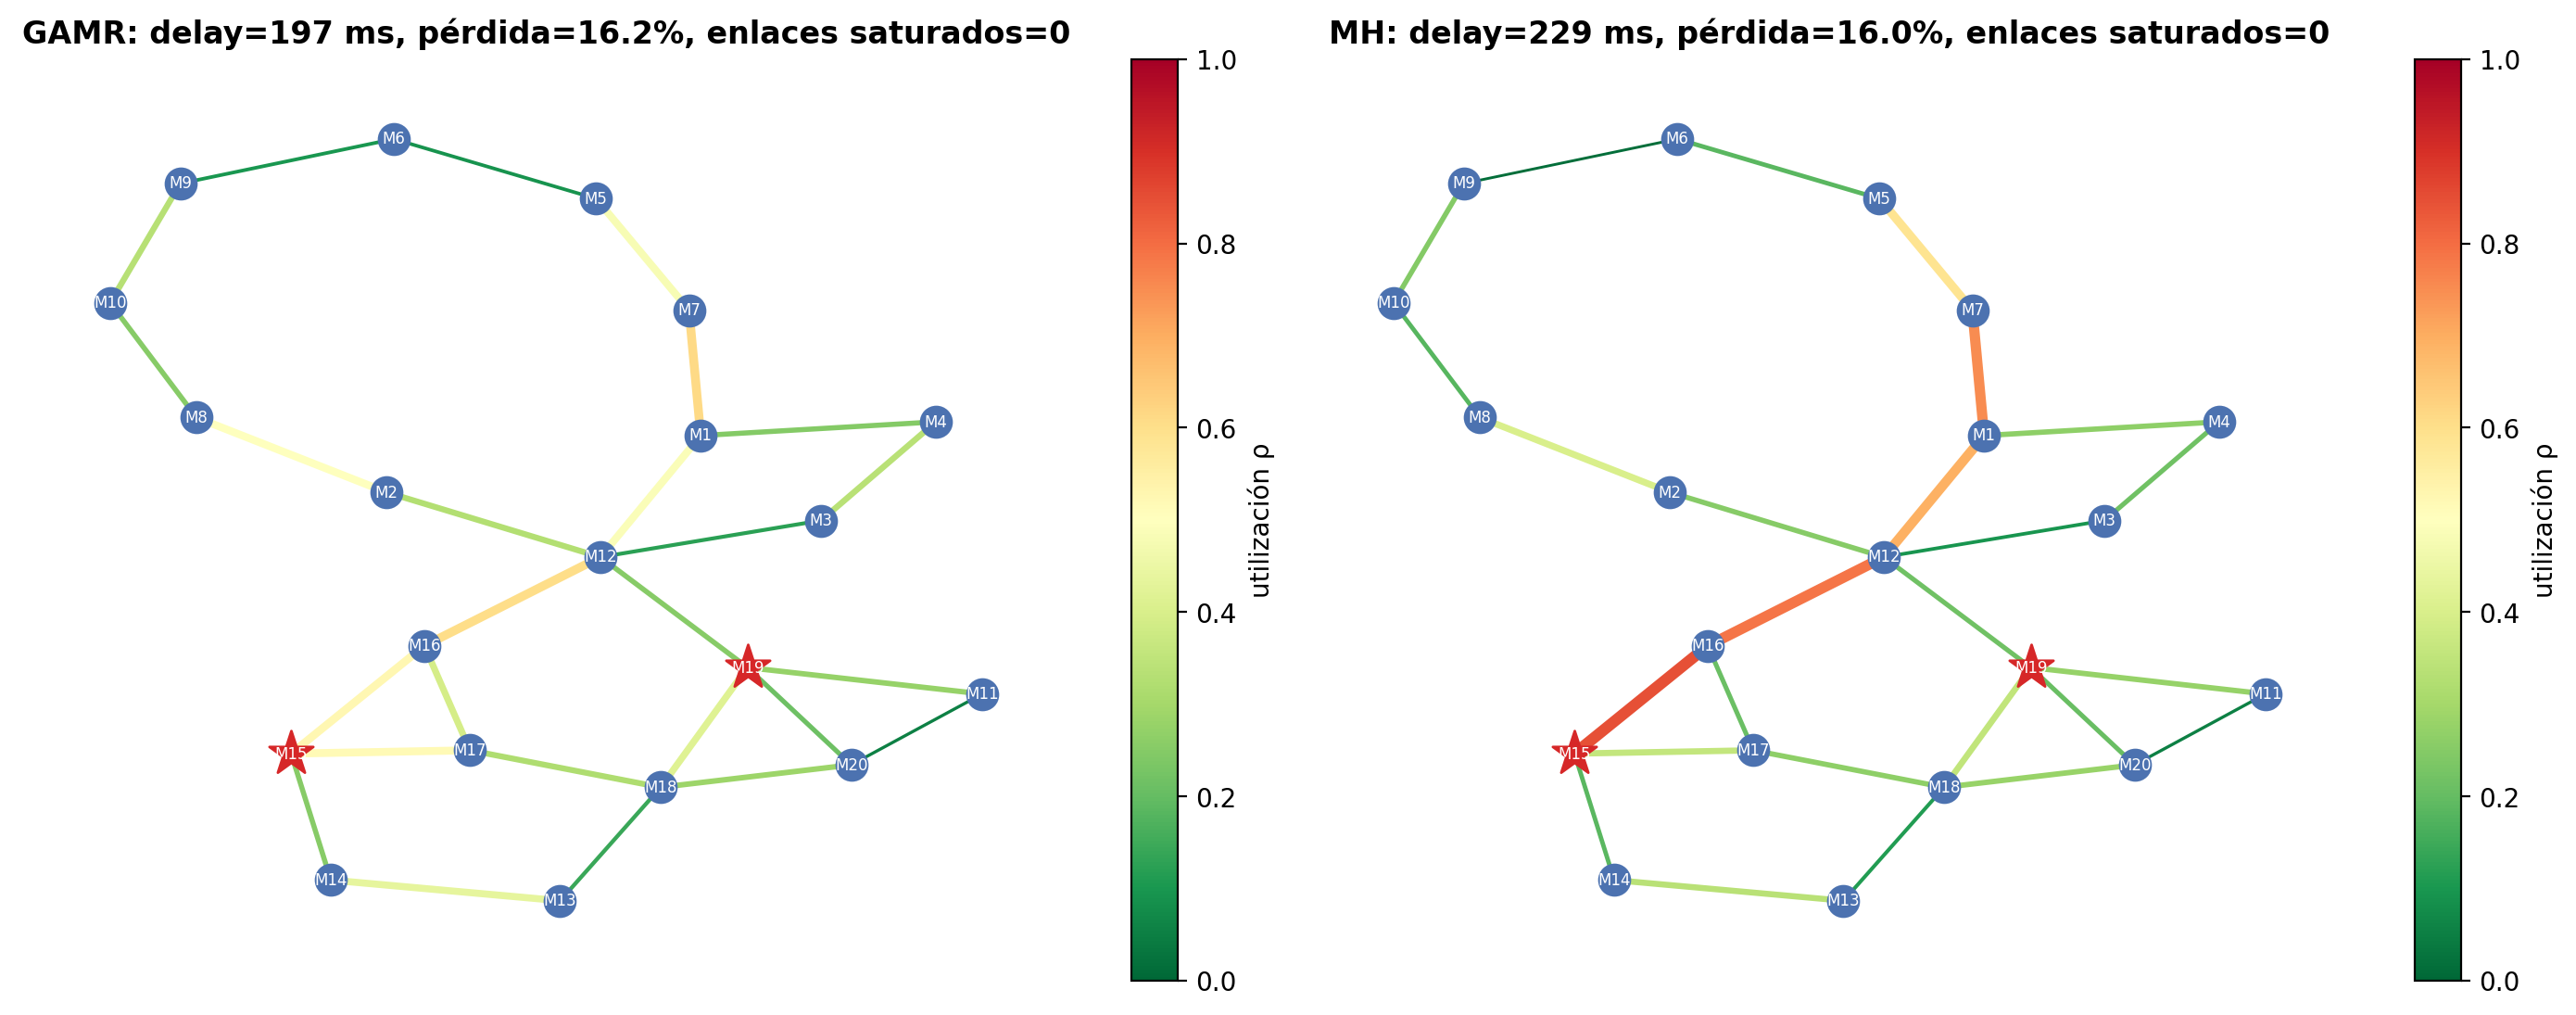

In [2]:
display(resumen_topologias())
resumen_sem = RAIZ / 'results' / 'replicacion_seminario' / 'resumen_resultados.md'
if resumen_sem.exists():
    display(Markdown(resumen_sem.read_text(encoding='utf-8')))
img = RAIZ / 'results' / 'replicacion_seminario' / 'fig_exp1_mapa_utilizacion.png'
if img.exists():
    display(Image(filename=str(img), width=900))

## 4. Debilidades de GAMR y qué ataca F-GAMR

| # | Debilidad (evidencia) | ¿F-GAMR la ataca? |
|---|---|---|
| 1 | α, pₘ fijos y ciegos al entorno | Se intentó (FIS adaptativo) y **se refutó** en validación → no se incluye |
| 2 | Elección final por menor solapamiento, ignora retardo/pérdida | **Sí — FIS-2** |
| 3 | PRSM de 1 ruta por servidor y BFS sin pesos | No (trabajo futuro) |
| 4 | RSBI y mutación eligen vecinos uniformemente, ciegos a la QoS | **Sí — FIS-1** |

## 5. Método propuesto: F-GAMR

```
                    estado medido Δᵗ (monitoreo LLDP: delay, loss, bw, carga)
                                     │
                 ┌───────────────────┴──────────────────┐
                 ▼                                      │
   FIS-1: w(u→v | S) = Mamdani(progreso, retardo, pérdida, carga)
                 │  ruleta  P(v) ∝ w^κ + ε
   ┌─────────────┼──────────────────────────────────┐   │
   │  Inicialización híbrida (α = 0.5)              │   │
   │    PSBI (memoria PRSM + BFS)  │  RSBI GUIADA ◄──┘   │
   │  Cruce multi-punto en Ω  →  Mutación GUIADA         │
   │  Eliminación de ciclos → Selección NSGA-II          │
   │  Parada ε(G) = 0 (HV estancado 10 generaciones)     │
   └──────────────────────────┬──────────────────────────┘
                              ▼ frente de Pareto F¹
         FIS-2: aptitud = Mamdani(retardo, pérdida)  →  argmax  →  reglas OpenFlow
                              ▼
                     actualización de la memoria PRSM
```

### 5.1 Lógica difusa (Mamdani)
Cada sistema usa funciones de pertenencia triangulares/trapezoidales, conjunción por **mínimo**, implicación por **mínimo** (recorte), agregación por **máximo** y defuzzificación por **centroide**:
$$y^* = \frac{\int y\,\mu_{\text{agr}}(y)\,dy}{\int \mu_{\text{agr}}(y)\,dy},\qquad \mu_{\text{agr}}(y)=\max_r \min\big(\tau_r,\ \mu_{B_r}(y)\big),\qquad \tau_r=\min_{i\in r}\mu_{A_{r,i}}(x_i)$$
Implementación propia y vectorizada en `src/fuzzy_logic.py` (sin `scikit-fuzzy`, para que la reproducción no dependa de una librería poco mantenida).

### 5.2 FIS-1: deseabilidad QoS de movimientos (exploración guiada)
Para un movimiento $u\to v$ dentro de una ruta hacia el servidor $S$, con el estado **medido** del intervalo:
$$\pi_{uv}=\tfrac12\big(h_S(u)-h_S(v)+1\big)\in\{0,\tfrac12,1\},\quad d_e=\tfrac{delay_e}{100\,\text{ms}},\quad l_e=\tfrac{loss_e}{10\,\%},\quad c_e=\tfrac{bg_e^t}{bw_e^t}$$
donde $h_S$ son los saltos al servidor (aleja / mismo nivel / acerca). FIS-1 entrega $w_{uv}\in[0,1]$ y la caminata RSBI elige el siguiente nodo con
$$P(v\mid u)=\frac{w_{uv}^{\kappa}+\varepsilon}{\sum_{v'\in\mathcal{N}(u)\setminus\text{visitados}} \big(w_{uv'}^{\kappa}+\varepsilon\big)},\qquad \kappa=2,\ \varepsilon=0.01$$
conservando el *backtracking* de RSBI. Con $\varepsilon>0$ **ningún movimiento válido queda prohibido** → se mantiene la exploración (no es un Dijkstra disfrazado). La mutación elige $\tilde\lambda\in\gamma$ con $P\propto q(\lambda_1,\tilde\lambda)\,q(\tilde\lambda,\lambda_2)$, donde $q$ es la deseabilidad con progreso neutro.

FIS-1: 10 reglas (κ = 2.0)
  R 1: SI progreso es Acerca Y retardo es Bajo Y perdida es Bajo ENTONCES deseabilidad es MuyAlta
  R 2: SI progreso es Acerca Y carga es Baja ENTONCES deseabilidad es Alta
  R 3: SI progreso es Acerca Y retardo es Medio ENTONCES deseabilidad es Alta
  R 4: SI progreso es Acerca Y retardo es Alto ENTONCES deseabilidad es Media
  R 5: SI progreso es Acerca Y perdida es Alto ENTONCES deseabilidad es Media
  R 6: SI progreso es Neutro Y retardo es Bajo Y perdida es Bajo ENTONCES deseabilidad es Media
  R 7: SI progreso es Neutro Y retardo es Alto ENTONCES deseabilidad es Baja
  R 8: SI progreso es Aleja Y retardo es Bajo Y carga es Baja ENTONCES deseabilidad es Baja
  R 9: SI progreso es Aleja ENTONCES deseabilidad es MuyBaja
  R10: SI carga es Alta ENTONCES deseabilidad es Baja


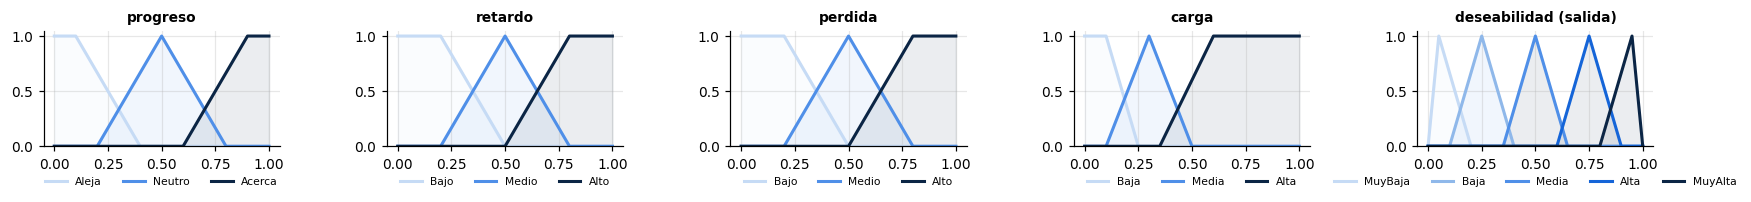

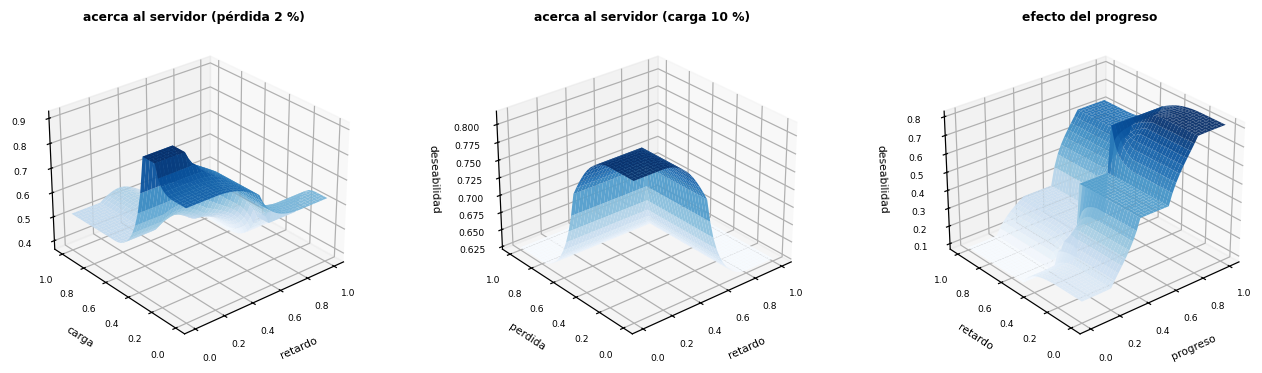

In [3]:
print(f'FIS-1: {len(FIS1.reglas)} reglas (κ = {KAPPA})')
for i, r in enumerate(FIS1.tabla_reglas(), 1):
    print(f'  R{i:>2}: {r}')
fig = plots.fig_pertenencia(FIS1, ncols=5)
plots.guardar(fig, DIR_NB, 'fis1_pertenencia'); plt.show()
fig = plots.fig_superficies([
    (FIS1, 'retardo', 'carga', 'deseabilidad', {'progreso': 1.0, 'perdida': 0.2}, 'acerca al servidor (pérdida 2 %)'),
    (FIS1, 'retardo', 'perdida', 'deseabilidad', {'progreso': 1.0, 'carga': 0.1}, 'acerca al servidor (carga 10 %)'),
    (FIS1, 'progreso', 'retardo', 'deseabilidad', {'perdida': 0.2, 'carga': 0.1}, 'efecto del progreso')])
plots.guardar(fig, DIR_NB, 'fis1_superficies'); plt.show()

**Lectura:** moverse hacia el servidor por un enlace de bajo retardo, baja pérdida y poca carga es "muy deseable" (≈ 0.9); alejarse es "muy poco deseable" pero no imposible. Así la caminata aleatoria se concentra en rutas QoS-prometedoras **sin perder diversidad**.

La guía se recalcula en cada intervalo con el estado medido (la carga $c_e$ cambia con β), así que **se adapta a la dinámica de la red sin entrenamiento**. Visualización sobre Oxford (flechas más oscuras/gruesas = movimiento más deseable hacia el servidor ★):

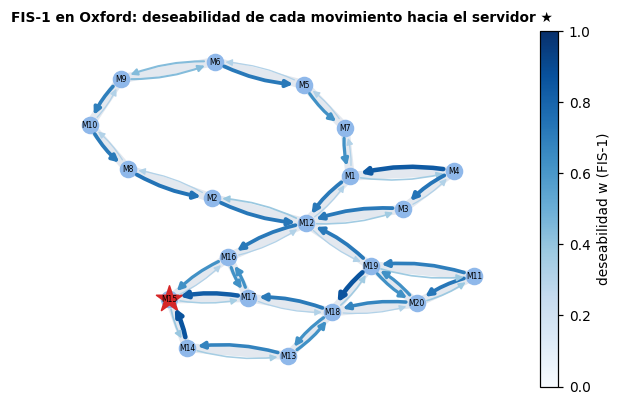

,retardo medio [ms],pérdida media,f3 (utilización cuello de botella),rutas distintas (de 2000)
RSBI uniforme (GAMR),540.650,0.452,0.289,36
RSBI guiada (FIS-1),485.102,0.358,0.302,22


In [4]:
g_ox, _ = cargar_topologia('Oxford')
red_demo = RedSDN(g_ox, n_servidores=2, beta=0.2, semilla=2025)
guia_demo = construir_guia(red_demo, red_demo.servidores)
pos_ox = nx.kamada_kawai_layout(g_ox)
fig = plots.fig_guia(red_demo, guia_demo, red_demo.servidores[0], pos_ox,
                     'FIS-1 en Oxford: deseabilidad de cada movimiento hacia el servidor ★')
plots.guardar(fig, DIR_NB, 'fis1_guia_oxford'); plt.show()

# ¿Qué cambia en las rutas iniciales? 2 000 caminatas RSBI uniformes vs guiadas para la misma solicitud
from src.gamr_original import rsbi
from src.proposed_method import rsbi_guiado
h, s = red_demo.hosts[5], red_demo.servidores[0]
ev = Evaluador(red_demo, [(h, s, 1.0)])
rnd = random.Random(0)
uni = [ev.evaluar([rsbi(red_demo, h, s, rnd)])[0] for _ in range(2000)]
gui = [ev.evaluar([rsbi_guiado(red_demo, h, s, rnd, guia_demo)])[0] for _ in range(2000)]
comp = pd.DataFrame({'RSBI uniforme (GAMR)': np.mean(uni, axis=0), 'RSBI guiada (FIS-1)': np.mean(gui, axis=0)},
                    index=['retardo medio [ms]', 'pérdida media', 'f3 (utilización cuello de botella)']).T
comp['rutas distintas (de 2000)'] = [len({tuple(np.round(x, 6)) for x in uni}), len({tuple(np.round(x, 6)) for x in gui})]
display(comp.round(3))

### 5.3 FIS-2: selector difuso de compromiso del frente
GAMR instala la solución del frente con **menor solapamiento de enlaces**, criterio topológico que no mira la QoS del usuario. FIS-2 recibe, para cada solución del frente $\mathcal{F}^1$, el retardo y la pérdida medios **normalizados min–max dentro del frente** y entrega una aptitud; se instala
$$\Phi^\star=\arg\max_{\Phi\in\mathcal{F}^1}\ \text{FIS-2}\big(\hat{\mathcal{D}}(\Phi),\hat{\mathcal{L}}(\Phi)\big)\quad(\text{empate}\to\text{menor retardo}).$$
Las 6 reglas expresan un compromiso: "ambos bajos" es lo mejor; "uno bajo y el otro medio" es bueno; cualquiera "alto" es malo. La normalización dentro del frente hace que el selector sea **invariante a la escala** de cada instancia.

FIS-2: 6 reglas
  R1: SI delay es Bajo Y perdida es Bajo ENTONCES aptitud es MuyAlta
  R2: SI delay es Bajo Y perdida es Medio ENTONCES aptitud es Alta
  R3: SI delay es Medio Y perdida es Bajo ENTONCES aptitud es Alta
  R4: SI delay es Medio Y perdida es Medio ENTONCES aptitud es Media
  R5: SI delay es Alto ENTONCES aptitud es Baja
  R6: SI perdida es Alto ENTONCES aptitud es Baja


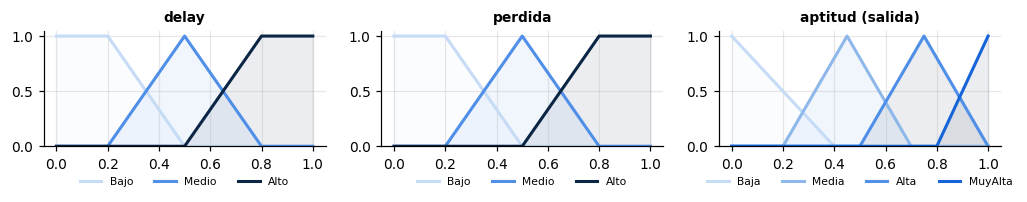

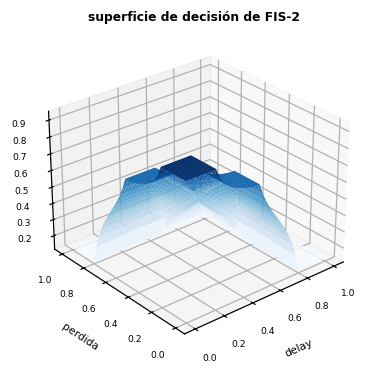

In [5]:
print(f'FIS-2: {len(FIS2.reglas)} reglas')
for i, r in enumerate(FIS2.tabla_reglas(), 1):
    print(f'  R{i}: {r}')
fig = plots.fig_pertenencia(FIS2, ncols=3)
plots.guardar(fig, DIR_NB, 'fis2_pertenencia'); plt.show()
fig = plots.fig_superficies([(FIS2, 'delay', 'perdida', 'aptitud', {}, 'superficie de decisión de FIS-2')])
plots.guardar(fig, DIR_NB, 'fis2_superficie'); plt.show()

### 5.4 Costo computacional
* **FIS-1:** se evalúa una vez por intervalo para todos los movimientos $(u,v,S)$: $\mathcal{O}(N_s\,|\mathcal{E}|\,R\,U)$ con $R=10$ reglas y $U=201$ puntos del universo (vectorizado). Dentro del AG, la ruleta cuesta lo mismo que la elección uniforme: $\mathcal{O}(\deg(u))$ por paso.
* **FIS-2:** una evaluación sobre el frente final, $\mathcal{O}(|\mathcal{F}^1|\,R\,U)$.
* La complejidad de GAMR, $\mathcal{O}\big(G^{\max}(NN_r|\mathcal{V}|^2+|\mathcal{E}|+4mN^2)\big)$, **no cambia**; el tiempo real incluso baja porque la guía converge en menos generaciones (Sección 10).

## 6. Demostración en una instancia (Oxford, Nₛ = 2, Nᵣ = 50, β = 20 %)

Se ejecutan GAMR y F-GAMR sobre **la misma red y las mismas solicitudes** durante dos intervalos (en el primero se llena la memoria PRSM). Se muestran la convergencia del hipervolumen con una escala común, el frente obtenido con la solución que instalaría cada criterio y la QoS medida en el estado realizado Δᵗ⁺¹.

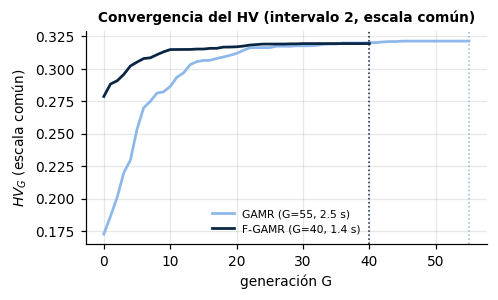

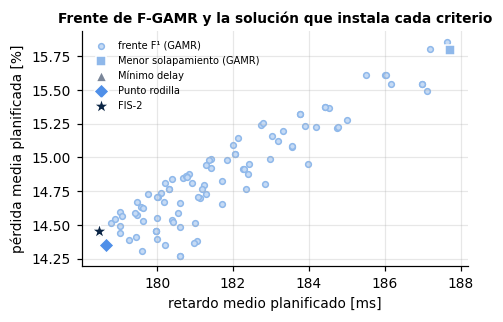

,HV,IGD,generaciones,tiempo_s,delay_ms,loss_pct,util_pct,rho_max_pct,enlaces_usados_pct,enlaces_saturados,satisf_bw_pct,saltos
algoritmo,,,,,,,,,,,,
GAMR,0.682,0.010,55,2.541,190.017,16.022,25.820,45.279,100.000,0,100.0,3.08
F-GAMR,0.656,0.025,40,1.425,181.451,14.454,26.103,52.400,76.923,0,100.0,3.20


In [6]:
red_i = RedSDN(g_ox, n_servidores=2, beta=0.2, semilla=2025)
algs_i = {'GAMR': GAMR(red_i, semilla=1), 'F-GAMR': FGAMR(red_i, semilla=1)}
for t in (1, 2):
    sol_i = red_i.generar_solicitudes(50, 2)
    r_g = algs_i['GAMR'].resolver(sol_i)
    r_f = algs_i['F-GAMR'].resolver(sol_i, escala=r_g['escala'])
    if t == 1:
        red_i.nuevo_intervalo()
res_i = {'GAMR': r_g, 'F-GAMR': r_f}
fig = plots.fig_convergencia(res_i, 'Convergencia del HV (intervalo 2, escala común)')
plots.guardar(fig, DIR_NB, 'demo_convergencia'); plt.show()

hv_igd = metricas_conjuntas({k: r['frente'] for k, r in res_i.items()})
# Criterios de elección aplicados al MISMO frente de F-GAMR
ind = r_f['individuos_frente']
att = atributos_frente(red_i, r_f['evaluador'], ind)
F = np.column_stack([att['delay'], att['perdida']])
rango = np.ptp(F, axis=0)
elegidos = {'Menor solapamiento (GAMR)': int(np.lexsort((att['delay'], att['solapamiento']))[0]),
            'Mínimo delay': int(np.argmin(att['delay'])),
            'Punto rodilla': int(np.argmin(np.linalg.norm((F - F.min(0)) / np.where(rango > 0, rango, 1), axis=1))),
            'FIS-2': int(np.lexsort((att['delay'], -np.round(aptitud_difusa(att), 9)))[0])}
fig = plots.fig_frente_seleccion(F, elegidos, 'Frente de F-GAMR y la solución que instala cada criterio')
plots.guardar(fig, DIR_NB, 'demo_seleccion'); plt.show()

red_i.nuevo_intervalo()                      # la red evoluciona con las rutas instaladas → QoS realizada
filas = []
for k, r in res_i.items():
    filas.append(dict(algoritmo=k, HV=hv_igd[k][0], IGD=hv_igd[k][1], generaciones=r['generaciones'],
                      tiempo_s=r['tiempo'], **evaluar_qos(red_i, sol_i, r['rutas'])))
display(pd.DataFrame(filas).set_index('algoritmo').round(3))

**Lectura:** la curva de F-GAMR parte más arriba (su población inicial ya contiene rutas QoS-prometedoras) y alcanza un HV mayor, normalmente en menos generaciones. En el frente, "menor solapamiento" puede caer en cualquier zona del compromiso, mientras que FIS-2 elige consistentemente una solución equilibrada (retardo y pérdida simultáneamente bajos). Una sola instancia **no es evidencia**: la evidencia estadística está en las Secciones 10–13.

## 7. Calibración en semillas de validación (500–503)

Todos los parámetros de diseño se fijaron **antes** de mirar las semillas de evaluación, con `python scripts/calibracion.py` (Oxford y Chinanet, β ∈ {5 %, 55 %}, Nₛ = 2, Nᵣ = 50, 4 semillas × 3 intervalos con memoria).

In [7]:
DIR_CAL = RAIZ / 'results' / 'calibracion'
cols = ['HV', 'IGD', 'tiempo', 'gen', 'alpha', 'delay_ms', 'loss_pct']
for nombre, titulo in [('etapaA_controlador_adaptativo', 'Etapa A — controlador difuso de α / inmigrantes (DESCARTADO)'),
                       ('etapaB_kappa', 'Etapa B — exploración guiada por FIS-1, κ ∈ {1, 2, 4} (κ = 2 ADOPTADO)')]:
    d = pd.read_csv(DIR_CAL / f'{nombre}.csv')
    display(Markdown(f'**{titulo}** (media de t ≥ 2)'))
    display(d[d.t >= 2].groupby(['topo', 'beta', 'alg'])[[c for c in cols if c in d]].mean().round(3))

sel = pd.read_csv(DIR_CAL / 'etapaC_selectores.csv')
g = sel.groupby(['topo', 'beta', 'selector'])[['delay_ms', 'loss_pct']].mean()
ref = g.xs('Menor solapamiento (GAMR)', level='selector')
rel = (100 * (g / ref.reindex(g.index.droplevel('selector')).values - 1)).round(2)
display(Markdown('**Etapa C — bases de reglas de FIS-2: Δ% de la QoS realizada vs "menor solapamiento"** (negativo = mejor)'))
display(rel.unstack('selector'))

**Etapa A — controlador difuso de α / inmigrantes (DESCARTADO)** (media de t ≥ 2)

HV    IGD  tiempo     gen  alpha  delay_ms  loss_pct
topo     beta alg                                                                         
Chinanet 0.05 GAMR                 0.714  0.055  10.318  83.083  0.500   125.372     7.862
              alpha + inmigrantes  0.699  0.061  13.777  85.167  0.635   123.882     7.989
              alpha adaptativo     0.701  0.065   9.844  73.917  0.635   126.522     8.055
              solo inmigrantes     0.670  0.078  12.531  73.417  0.500   125.914     7.983
         0.55 GAMR                 0.733  0.065   9.338  77.833  0.500   127.241     8.151
              alpha + inmigrantes  0.724  0.062  15.076  76.333  0.253   132.875     8.100
              alpha adaptativo     0.753  0.054  10.550  88.333  0.253   130.271     7.977
              solo inmigrantes     0.726  0.072  13.859  83.083  0.500   127.229     8.169
Oxford   0.05 GAMR                 0.662  0.051   7.952  63.833  0.500   186.593    12.950
              alpha + inmigrantes  0.665  0.058   7.584  55.250  0.629   188.170    12.966
              alpha adaptativo     0.638  0.062   6.887  55.417  0.629   187.871    12.921
              solo inmigrantes     0.638  0.069   8.571  59.833  0.500   187.242    12.952
         0.55 GAMR                 0.625  0.095   7.016  57.417  0.500   189.097    12.862
              alpha + inmigrantes  0.662  0.074  12.064  69.500  0.250   190.293    12.896
              alpha adaptativo     0.662  0.055   8.137  68.750  0.250   191.427    12.838
              solo inmigrantes     0.675  0.056   9.885  62.167  0.500   189.553    12.796

**Etapa B — exploración guiada por FIS-1, κ ∈ {1, 2, 4} (κ = 2 ADOPTADO)** (media de t ≥ 2)

HV    IGD  tiempo     gen  delay_ms  loss_pct
topo     beta alg                                                        
Chinanet 0.05 FIS-1 k=1  0.700  0.072   9.642  78.750   124.850     7.894
              FIS-1 k=2  0.743  0.048   9.141  77.083   123.650     7.929
              FIS-1 k=4  0.731  0.057   8.081  69.083   123.444     8.033
              GAMR       0.685  0.077   9.787  83.083   125.372     7.862
         0.55 FIS-1 k=1  0.733  0.052   9.029  80.083   126.455     8.078
              FIS-1 k=2  0.760  0.048   6.849  64.583   130.419     7.987
              FIS-1 k=4  0.749  0.050   7.866  75.750   127.813     7.888
              GAMR       0.665  0.085   8.263  77.833   127.241     8.151
Oxford   0.05 FIS-1 k=1  0.661  0.047   7.209  52.417   187.023    12.806
              FIS-1 k=2  0.664  0.052   6.673  52.083   187.220    12.731
              FIS-1 k=4  0.640  0.069   5.457  44.917   187.790    12.748
              GAMR       0.640  0.059   7.354  63.833   186.593    12.950
         0.55 FIS-1 k=1  0.683  0.061   6.250  50.333   189.281    12.671
              FIS-1 k=2  0.657  0.075   5.980  48.417   188.896    12.796
              FIS-1 k=4  0.639  0.080   5.167  42.750   188.849    12.729
              GAMR       0.615  0.081   7.081  57.417   189.097    12.862

**Etapa C — bases de reglas de FIS-2: Δ% de la QoS realizada vs "menor solapamiento"** (negativo = mejor)

delay_ms                                                                                                                                   loss_pct  \
selector      A (+solapamiento, +volatilidad) B (retardo-pérdida, adoptada) C (sesgo a retardo) FIS-2 final (src) Menor solapamiento (GAMR) Mínimo delay A (+solapamiento, +volatilidad)   
topo     beta                                                                                                                                                                              
Chinanet 0.05                           -0.40                         -0.40               -0.60             -0.40                       0.0        -2.38                           -6.75   
         0.55                           -0.40                         -2.78               -3.13             -2.78                       0.0        -4.65                           -4.37   
Oxford   0.05                            1.50                          1.72                0.11              1.72                       0.0        -3.52                           -1.71   
         0.55                            1.15                          1.92               -0.15              1.92                       0.0        -3.27                            0.40   

                                                                                                                          
selector      B (retardo-pérdida, adoptada) C (sesgo a retardo) FIS-2 final (src) Menor solapamiento (GAMR) Mínimo delay  
topo     beta                                                                                                             
Chinanet 0.05                         -6.85               -5.98             -6.85                       0.0         0.97  
         0.55                         -6.78               -6.17             -6.78                       0.0         0.97  
Oxford   0.05                         -1.86                1.24             -1.86                       0.0         9.17  
         0.55                         -3.10                0.49             -3.10                       0.0         8.73

**Conclusiones de la calibración**
* **Etapa A:** adaptar α/inmigrantes según la volatilidad no mejora el HV de forma consistente y aumenta el tiempo; con α alto (0.8) en red estable el HV cae hasta 19 %. → descartado (se discute en la Sección 15).
* **Etapa B:** la guía difusa mejora el HV en los 4 escenarios; κ = 2 ofrece el mejor equilibrio (κ = 4 es demasiado codicioso: menos diversidad).
* **Etapa C:** la base retardo–pérdida (B) reduce la pérdida en los 4 escenarios con un costo de retardo acotado; agregar solapamiento/holgura/volatilidad no ayuda.

## 8. Protocolo experimental

| | E1 — comparación principal + ablación | E2 — escalabilidad | E3 — desorden de red |
|---|---|---|---|
| Topología | Oxford y Chinanet | Oxford | Chinanet |
| Servidores Nₛ | 2 | 2 | 2 |
| Solicitudes Nᵣ | 50 | 10, 20, 50, 100 | 100 |
| Desorden β (Ec. 14) | 5 %, 55 % | 20 % | 0, 5, 20, 55 % |
| Algoritmos | MH, QoS-Dijkstra, NSGA-II, GAMR, solo FIS-1, solo FIS-2, **F-GAMR** | MH, QoS-Dijkstra, GAMR, **F-GAMR** | MH, LCP-WAC*, GAMR, **F-GAMR** |
| Semillas independientes | **30** (0–29) | 10 | 10 |

* **Secuencia dinámica por semilla:** T = 4 intervalos. En cada uno el monitoreo mide Δᵗ, llegan Nᵣ solicitudes nuevas y **todos los algoritmos resuelven exactamente la misma instancia**. El intervalo 1 (memoria vacía) se descarta y las métricas se promedian sobre t = 2…4 → **una observación por semilla**.
* **QoS realizada:** las rutas se instalan y la red evoluciona a Δᵗ⁺¹ (Ec. 14 con el β del escenario). Retardo, pérdida, utilización máxima y satisfacción de ancho de banda se miden **en ese estado realizado**, no en el que se optimizó.
* **HV/IGD:** frentes de los evolutivos de cada instancia normalizados en conjunto (ideal/nadir de la unión), $r^{\text{ref}}=(1,1,1)$, $\mathcal{F}^*$ = no dominados de la unión (Ec. 16–17).
* **Estadística:** media ± desviación estándar sobre semillas; **Wilcoxon de rangos con signo pareado** por semilla (α = 0.05).
* **Parámetros (Tabla III):** N = 100, Gᵐᵃˣ = 500, Gᵖʳᵉ = 10, p_c = 0.8, p_m = 0.1, α = 0.5, torneo binario.
* **Líneas base:** Min-Hop (camino más corto en saltos), QoS-Dijkstra (mínimo retardo sobre enlaces con residual ≥ Bₖ), NSGA-II (α = 0, sin memoria), GAMR original y LCP-WAC* (proxy sin LSTM, solo en E3).

## 9. Ejecución (o carga) de los experimentos

In [8]:
tareas = configuraciones('completo' if MODO == 'completo' else 'rapido')
print(pd.Series([t['experimento'] for t in tareas]).value_counts().sort_index().to_string(), '\n')
t0 = time.time()
df, df_sel = cargar_o_ejecutar(DIR_CRUDOS, MODO, N_JOBS, RECALCULAR)
out = generar_reporte(df, df_sel, DIR_TABLAS, DIR_FIGS)
print(f'{len(df)} filas · {df.semilla.nunique()} semillas · {time.time() - t0:.0f} s')


def tabla_delta(t, filtro=None, col_grupo='esc'):
    """Pivote 'Δ% (> 0 = mejor) con * si p < 0.05' a partir de una tabla de comparar()."""
    t = t if filtro is None else t[filtro(t)]
    celda = t.apply(lambda r: f"{r.mejora_pct:+.1f}%{'*' if r.p_valor < 0.05 else ''}", axis=1)
    return t.assign(celda=celda).pivot_table(index=[col_grupo, 'algoritmo'], columns='metrica', values='celda', aggfunc='first')

E1    120
E2     40
E3     40 

Resultados cargados de [ruta local omitida]
Tablas en [ruta local omitida]
Figuras en [ruta local omitida]
4640 filas · 30 semillas · 9 s


## 10. E1 — Calidad del frente de Pareto y tiempo (30 semillas)

**Media ± std por semilla (evolutivos)**

HV            IGD     tiempo_s generaciones
esc              algoritmo                                                             
Chinanet · β=5%  NSGA-II         0.669 ± 0.069  0.087 ± 0.035  9.11 ± 1.84  89.7 ± 16.2
                 GAMR            0.679 ± 0.060  0.081 ± 0.026  7.44 ± 1.69  77.2 ± 16.1
                 F-GAMR (FIS-1)  0.729 ± 0.049  0.057 ± 0.015  6.56 ± 1.78  65.8 ± 17.5
                 F-GAMR (FIS-2)  0.691 ± 0.046  0.074 ± 0.026  7.83 ± 1.74  79.3 ± 16.3
                 F-GAMR          0.734 ± 0.055  0.061 ± 0.021  6.87 ± 1.67  68.4 ± 16.1
Chinanet · β=55% NSGA-II         0.675 ± 0.054  0.080 ± 0.028  9.50 ± 1.75  93.1 ± 16.2
                 GAMR            0.678 ± 0.048  0.077 ± 0.016  7.68 ± 1.70  77.6 ± 16.2
                 F-GAMR (FIS-1)  0.720 ± 0.035  0.064 ± 0.023  6.83 ± 1.56  66.3 ± 16.0
                 F-GAMR (FIS-2)  0.672 ± 0.049  0.081 ± 0.031  7.82 ± 1.54  76.3 ± 14.8
                 F-GAMR          0.724 ± 0.046  0.062 ± 0.024  7.13 ± 1.83  69.3 ± 17.7
Oxford · β=5%    NSGA-II         0.622 ± 0.072  0.094 ± 0.037  6.98 ± 1.21  69.3 ± 10.3
                 GAMR            0.687 ± 0.061  0.060 ± 0.023  6.14 ± 1.58  61.7 ± 13.7
                 F-GAMR (FIS-1)  0.695 ± 0.070  0.066 ± 0.026  5.01 ± 1.43  49.5 ± 12.6
                 F-GAMR (FIS-2)  0.690 ± 0.065  0.054 ± 0.015  6.23 ± 1.43  62.0 ± 12.3
                 F-GAMR          0.697 ± 0.073  0.067 ± 0.026  5.12 ± 1.31  50.8 ± 11.8
Oxford · β=55%   NSGA-II         0.635 ± 0.060  0.090 ± 0.032  6.93 ± 1.10  70.8 ± 11.8
                 GAMR            0.694 ± 0.066  0.059 ± 0.017  6.05 ± 1.40  62.2 ± 13.7
                 F-GAMR (FIS-1)  0.688 ± 0.062  0.066 ± 0.021  4.88 ± 1.12  48.4 ± 10.9
                 F-GAMR (FIS-2)  0.693 ± 0.059  0.057 ± 0.018  6.11 ± 1.20  61.2 ± 11.0
                 F-GAMR          0.698 ± 0.065  0.063 ± 0.028  4.94 ± 1.26  49.8 ± 12.5

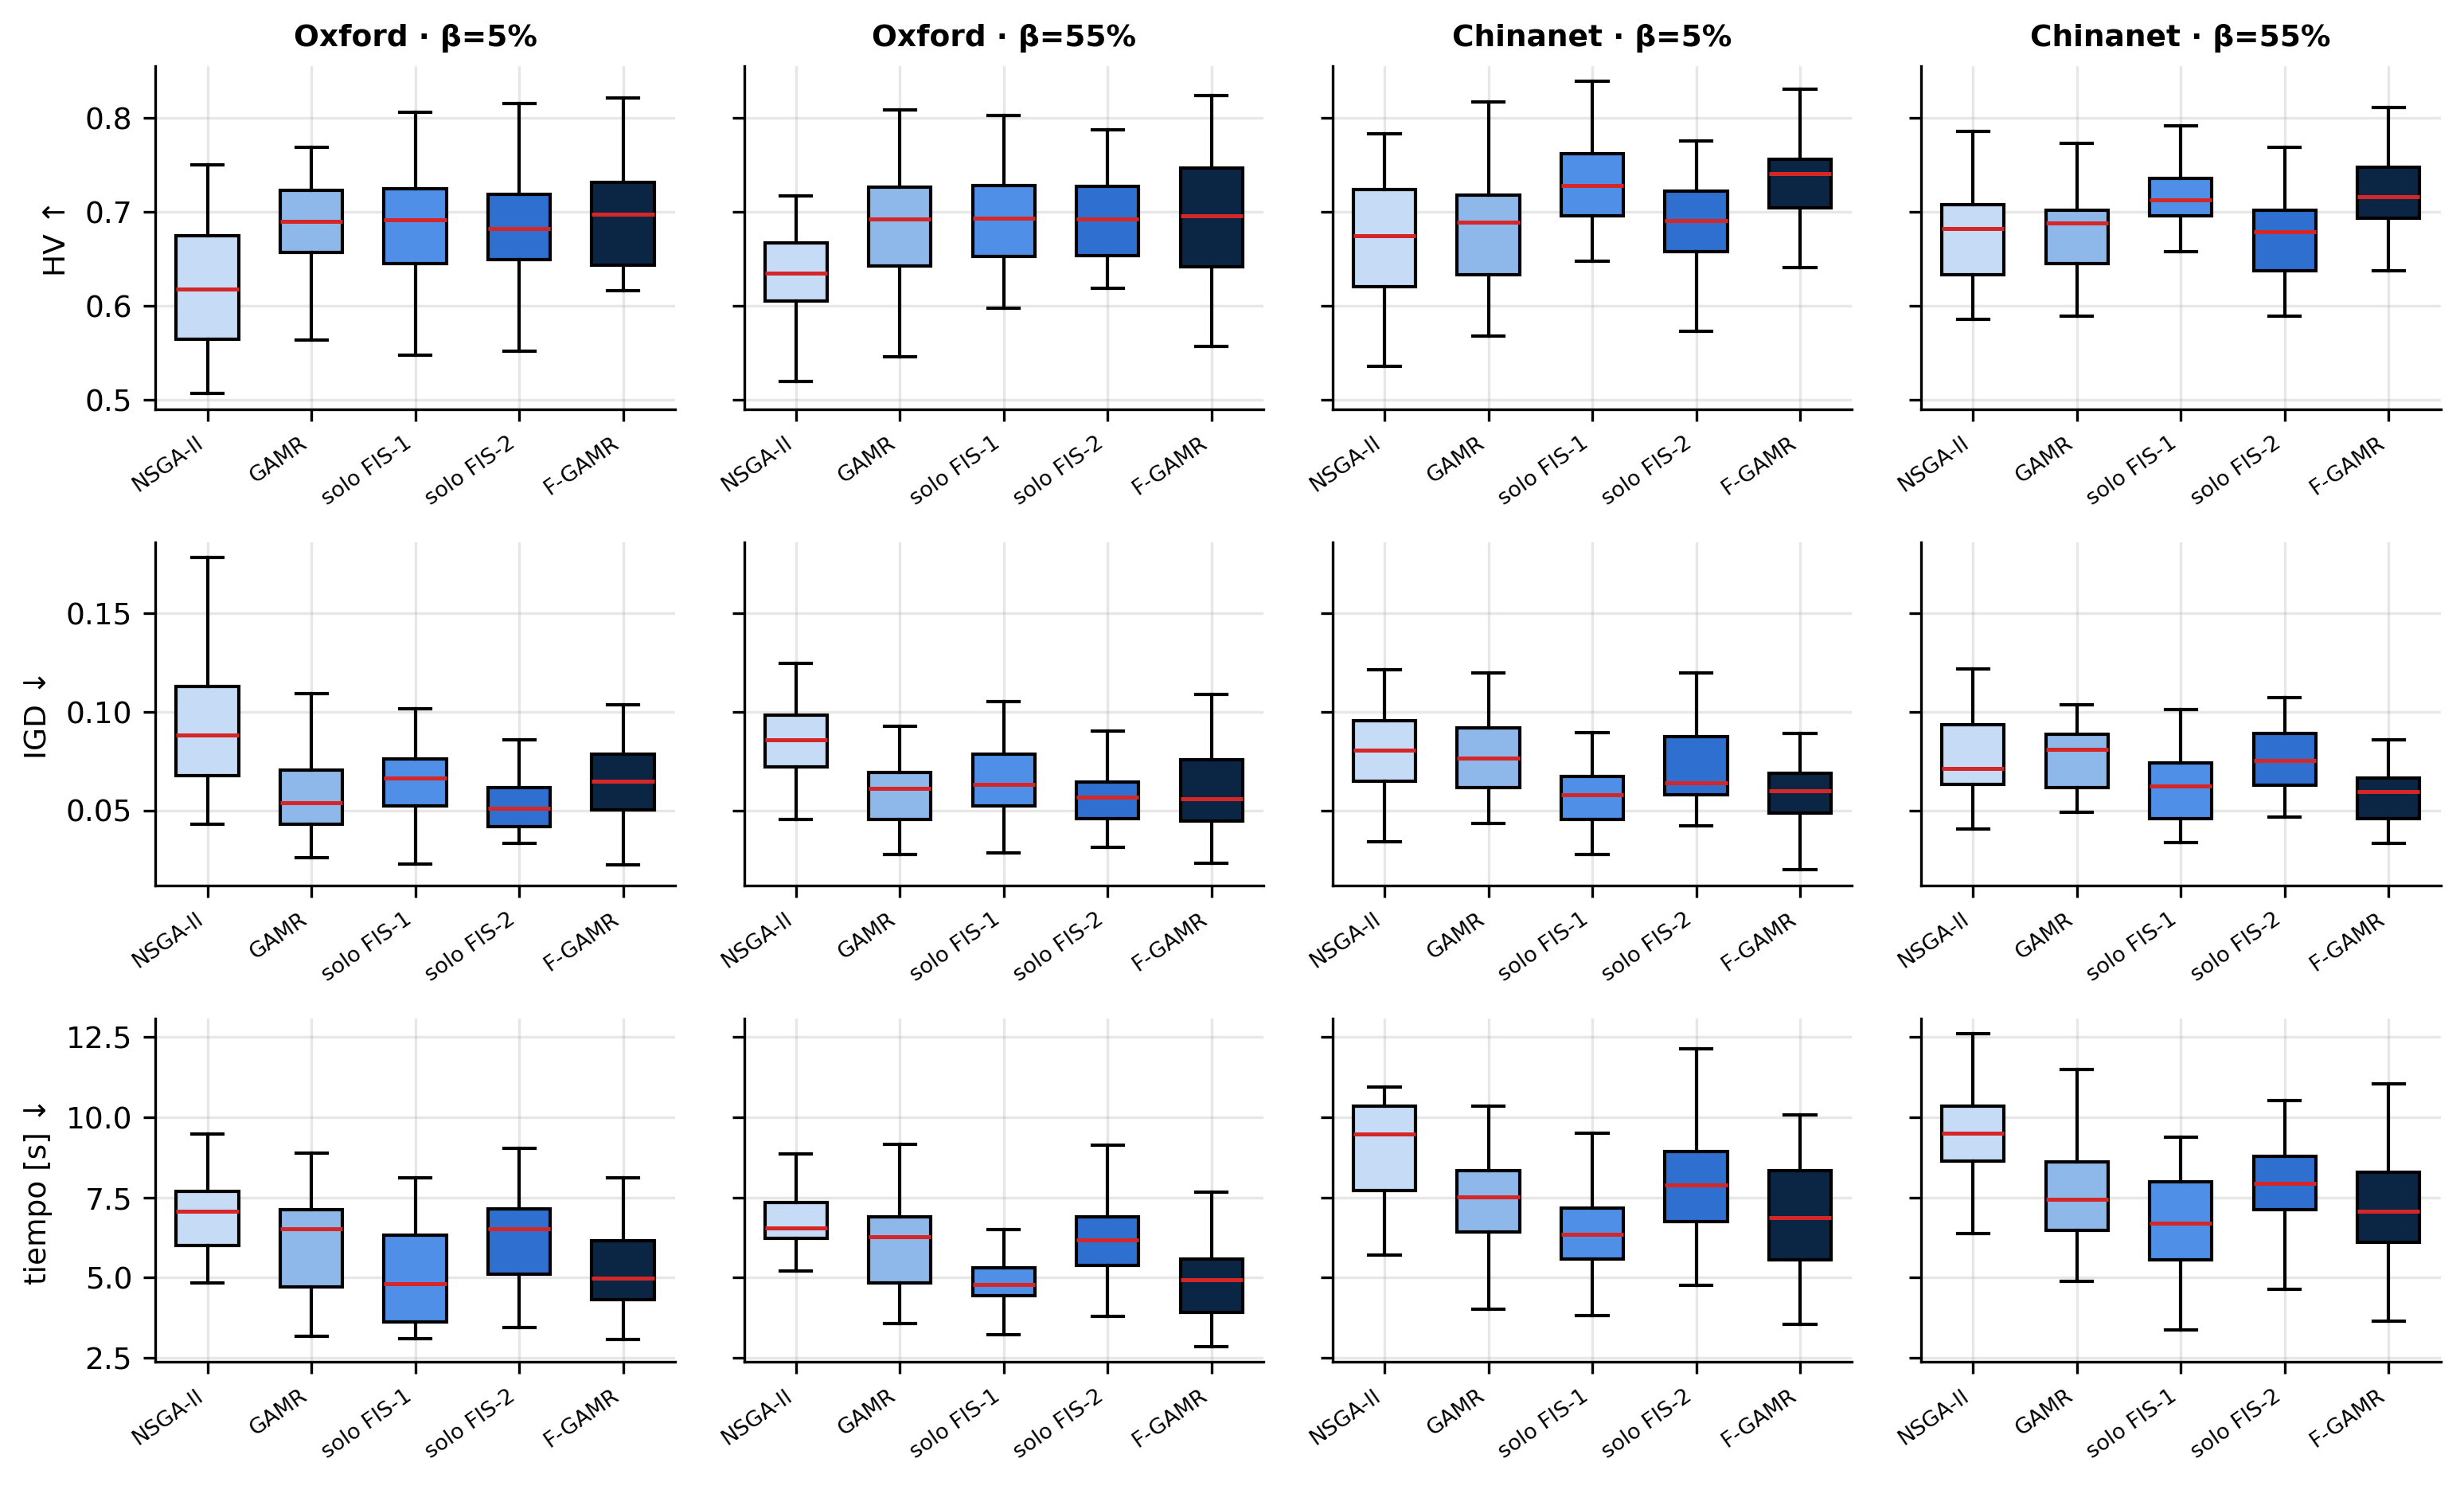

**Ablación: Δ% frente a GAMR original** (> 0 = mejor; * = Wilcoxon p < 0.05)

metrica                              HV      IGD  tiempo_s
esc              algoritmo                                
Chinanet · β=5%  F-GAMR          +8.2%*  +24.7%*    +7.7%*
                 F-GAMR (FIS-1)  +7.4%*  +29.6%*   +11.8%*
                 F-GAMR (FIS-2)   +1.8%    +8.5%     -5.2%
                 MH                 NaN      NaN  +100.0%*
                 NSGA-II          -1.4%    -7.7%   -22.3%*
                 QoS-Dijkstra       NaN      NaN   +99.7%*
Chinanet · β=55% F-GAMR          +6.8%*  +19.6%*    +7.3%*
                 F-GAMR (FIS-1)  +6.2%*  +16.7%*   +11.2%*
                 F-GAMR (FIS-2)   -0.9%    -5.2%     -1.8%
                 MH                 NaN      NaN  +100.0%*
                 NSGA-II          -0.5%    -3.2%   -23.7%*
                 QoS-Dijkstra       NaN      NaN   +99.7%*
Oxford · β=5%    F-GAMR           +1.5%   -11.5%   +16.7%*
                 F-GAMR (FIS-1)   +1.2%    -9.8%   +18.4%*
                 F-GAMR (FIS-2)   +0.5%    +9.8%     -1.5%
                 MH                 NaN      NaN  +100.0%*
                 NSGA-II         -9.4%*  -56.8%*   -13.7%*
                 QoS-Dijkstra       NaN      NaN   +99.8%*
Oxford · β=55%   F-GAMR           +0.5%    -7.8%   +18.3%*
                 F-GAMR (FIS-1)   -0.9%   -13.1%   +19.3%*
                 F-GAMR (FIS-2)   -0.2%    +2.4%     -1.1%
                 MH                 NaN      NaN  +100.0%*
                 NSGA-II         -8.6%*  -52.4%*   -14.6%*
                 QoS-Dijkstra       NaN      NaN   +99.8%*

In [9]:
display(Markdown('**Media ± std por semilla (evolutivos)**'))
display(out['E1_moo'])
display(Image(filename=str(DIR_FIGS / 'E1_cajas_moo.png'), width=1000))
display(Markdown('**Ablación: Δ% frente a GAMR original** (> 0 = mejor; * = Wilcoxon p < 0.05)'))
display(tabla_delta(out['E1_ablacion'], lambda t: t.metrica.isin(['HV', 'IGD', 'tiempo_s']))) 

## 11. E1 — QoS realizada y análisis de la selección final

**Media ± std por semilla (todos los algoritmos)**

delay_ms      loss_pct  rho_max_pct satisf_bw_pct
esc              algoritmo                                                            
Chinanet · β=5%  MH              169.7 ± 47.6  11.33 ± 4.07  68.3 ± 19.1   92.5 ± 15.9
                 QoS-Dijkstra    184.1 ± 45.2  16.00 ± 8.16  81.6 ± 17.3   81.6 ± 22.5
                 NSGA-II         166.9 ± 45.6  10.80 ± 3.88  65.7 ± 20.1   92.5 ± 15.9
                 GAMR            166.5 ± 45.5  10.77 ± 3.92  65.2 ± 20.4   92.5 ± 15.9
                 F-GAMR (FIS-1)  164.5 ± 45.6  10.82 ± 3.92  64.9 ± 20.5   92.5 ± 15.9
                 F-GAMR (FIS-2)  168.4 ± 47.4  10.14 ± 4.02  67.2 ± 19.1   92.5 ± 15.9
                 F-GAMR          166.9 ± 47.3  10.11 ± 4.01  67.8 ± 18.8   92.5 ± 15.9
Chinanet · β=55% MH              179.1 ± 55.0  11.83 ± 4.07  73.3 ± 17.2   91.1 ± 16.5
                 QoS-Dijkstra    203.3 ± 59.9  17.60 ± 7.64  84.4 ± 17.0   75.9 ± 23.7
                 NSGA-II         177.2 ± 54.0  11.35 ± 3.96  70.3 ± 18.5   91.1 ± 16.4
                 GAMR            174.3 ± 53.2  11.26 ± 3.99  69.9 ± 18.6   91.5 ± 16.5
                 F-GAMR (FIS-1)  173.5 ± 52.6  11.24 ± 3.98  70.3 ± 18.4   91.2 ± 16.4
                 F-GAMR (FIS-2)  178.2 ± 53.6  10.68 ± 4.03  71.9 ± 17.1   91.2 ± 16.4
                 F-GAMR          176.3 ± 53.9  10.66 ± 4.09  72.5 ± 16.8   91.1 ± 16.4
Oxford · β=5%    MH              224.8 ± 58.9  14.40 ± 5.03  77.4 ± 14.8   91.4 ± 16.7
                 QoS-Dijkstra    231.6 ± 79.9  16.19 ± 6.58  79.1 ± 14.9   86.4 ± 19.4
                 NSGA-II         199.6 ± 41.6  12.91 ± 3.51   65.4 ± 9.1    99.6 ± 1.9
                 GAMR            196.3 ± 41.2  12.85 ± 3.45   66.6 ± 9.4    99.2 ± 3.3
                 F-GAMR (FIS-1)  197.5 ± 43.3  12.81 ± 3.41   67.5 ± 9.9    99.6 ± 1.9
                 F-GAMR (FIS-2)  198.6 ± 42.7  12.50 ± 3.54   66.9 ± 8.9   100.0 ± 0.0
                 F-GAMR          198.9 ± 42.4  12.38 ± 3.56   68.2 ± 8.9    99.5 ± 2.0
Oxford · β=55%   MH              239.6 ± 61.4  16.20 ± 6.93  83.3 ± 12.4   83.8 ± 19.1
                 QoS-Dijkstra    247.4 ± 81.5  18.50 ± 7.64  84.9 ± 12.4   78.6 ± 21.8
                 NSGA-II         219.5 ± 54.8  13.38 ± 3.75  75.8 ± 12.1    94.4 ± 9.3
                 GAMR            216.7 ± 54.3  13.34 ± 3.79  76.1 ± 11.8    94.3 ± 7.2
                 F-GAMR (FIS-1)  216.6 ± 54.9  13.41 ± 3.96  76.4 ± 11.8    93.7 ± 8.5
                 F-GAMR (FIS-2)  218.3 ± 53.8  13.10 ± 3.89  75.8 ± 11.6    94.8 ± 7.7
                 F-GAMR          220.3 ± 55.0  12.97 ± 3.90  77.0 ± 11.7    93.3 ± 9.2

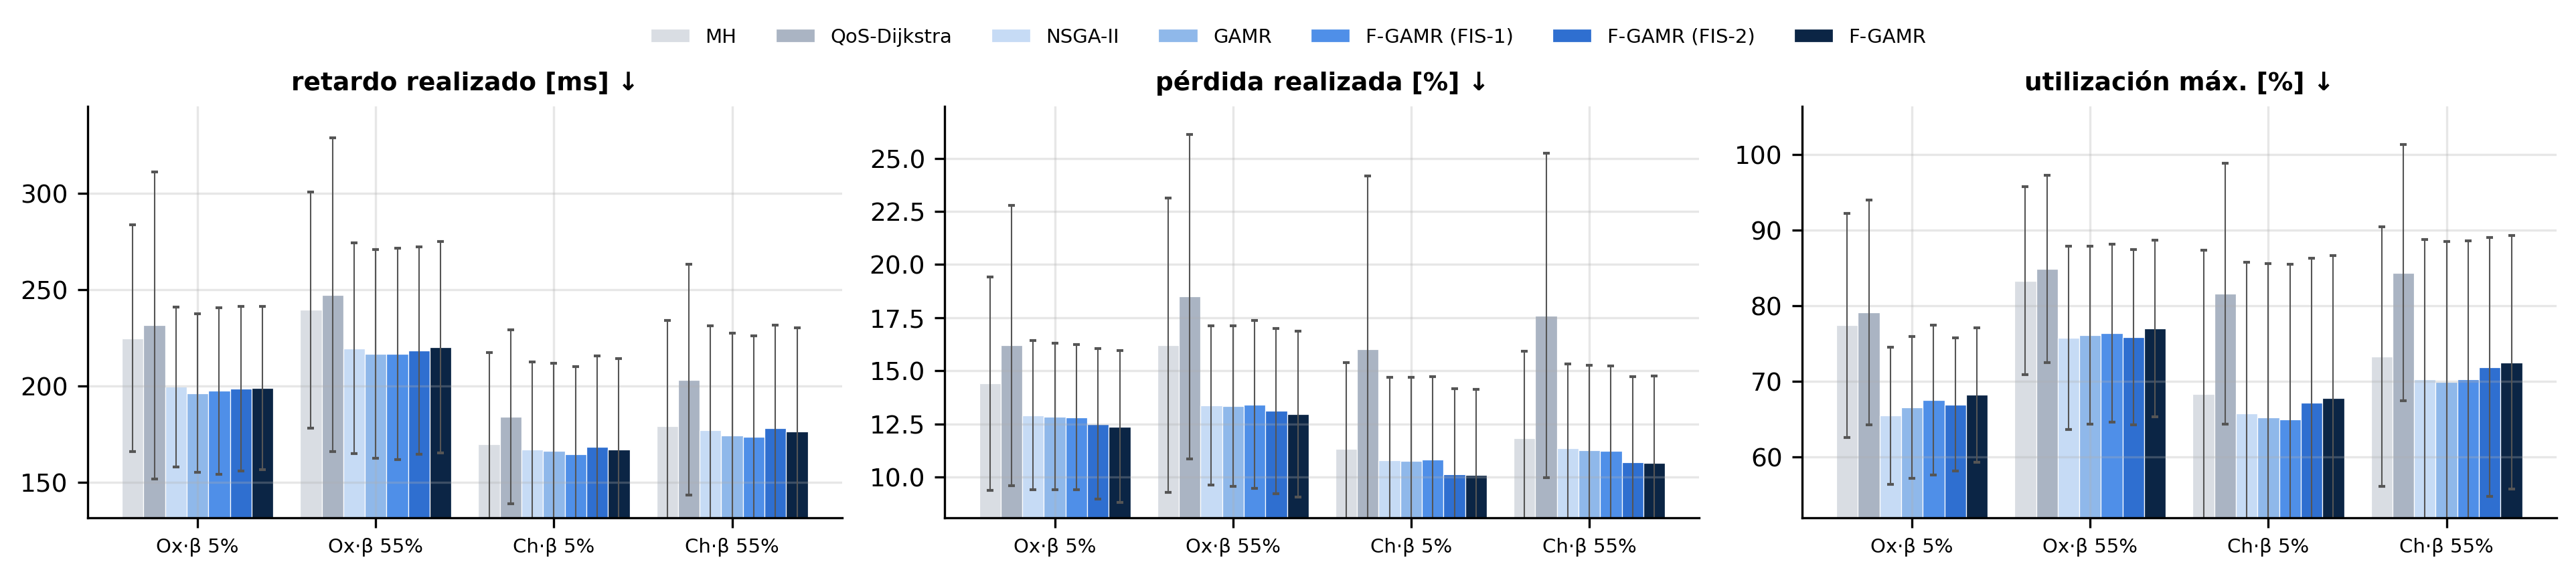

**F-GAMR frente a las tres líneas base** (Δ%, > 0 = mejor; * = p < 0.05)

metrica                                  HV      IGD delay_ms loss_pct      tiempo_s
esc              algoritmo                                                          
Chinanet · β=5%  F-GAMR vs GAMR      +8.2%*  +24.7%*    -0.3%   +6.1%*        +7.7%*
                 F-GAMR vs MH           NaN      NaN   +1.7%*  +10.8%*  -1659853.0%*
                 F-GAMR vs NSGA-II   +9.7%*  +30.1%*    -0.0%   +6.4%*       +24.6%*
Chinanet · β=55% F-GAMR vs GAMR      +6.8%*  +19.6%*    -1.2%   +5.3%*        +7.3%*
                 F-GAMR vs MH           NaN      NaN    +1.5%   +9.9%*  -1772800.9%*
                 F-GAMR vs NSGA-II   +7.3%*  +22.1%*    +0.5%   +6.1%*       +25.0%*
Oxford · β=5%    F-GAMR vs GAMR       +1.5%   -11.5%   -1.3%*   +3.7%*       +16.7%*
                 F-GAMR vs MH           NaN      NaN  +11.5%*  +14.0%*  -2845796.4%*
                 F-GAMR vs NSGA-II  +12.0%*  +28.9%*    +0.3%   +4.2%*       +26.7%*
Oxford · β=55%   F-GAMR vs GAMR       +0.5%    -7.8%    -1.6%   +2.8%*       +18.3%*
                 F-GAMR vs MH           NaN      NaN   +8.0%*  +19.9%*  -2731969.5%*
                 F-GAMR vs NSGA-II   +9.9%*  +29.2%*    -0.4%   +3.1%*       +28.8%*

**Ablación de la QoS frente a GAMR** (Δ%, * = p < 0.05)

metrica                         delay_ms loss_pct
esc              algoritmo                       
Chinanet · β=5%  F-GAMR            -0.3%   +6.1%*
                 F-GAMR (FIS-1)   +1.2%*    -0.5%
                 F-GAMR (FIS-2)   -1.2%*   +5.8%*
                 MH               -1.9%*   -5.2%*
                 NSGA-II           -0.2%    -0.3%
                 QoS-Dijkstra     -10.6%  -48.6%*
Chinanet · β=55% F-GAMR            -1.2%   +5.3%*
                 F-GAMR (FIS-1)    +0.4%    +0.2%
                 F-GAMR (FIS-2)   -2.3%*   +5.1%*
                 MH               -2.8%*   -5.1%*
                 NSGA-II          -1.7%*    -0.8%
                 QoS-Dijkstra    -16.6%*  -56.3%*
Oxford · β=5%    F-GAMR           -1.3%*   +3.7%*
                 F-GAMR (FIS-1)    -0.6%    +0.3%
                 F-GAMR (FIS-2)   -1.2%*   +2.7%*
                 MH              -14.5%*   -12.1%
                 NSGA-II          -1.7%*    -0.5%
                 QoS-Dijkstra    -18.0%*  -26.0%*
Oxford · β=55%   F-GAMR            -1.6%   +2.8%*
                 F-GAMR (FIS-1)    +0.0%    -0.5%
                 F-GAMR (FIS-2)    -0.7%    +1.8%
                 MH              -10.5%*  -21.4%*
                 NSGA-II          -1.3%*    -0.3%
                 QoS-Dijkstra    -14.1%*  -38.6%*

In [10]:
display(Markdown('**Media ± std por semilla (todos los algoritmos)**'))
display(out['E1_qos'])
display(Image(filename=str(DIR_FIGS / 'E1_barras_qos.png'), width=1000))
display(Markdown('**F-GAMR frente a las tres líneas base** (Δ%, > 0 = mejor; * = p < 0.05)'))
m = out['E1_mejoras'].copy()
m['algoritmo'] = 'F-GAMR vs ' + m['referencia']
display(tabla_delta(m))
display(Markdown('**Ablación de la QoS frente a GAMR** (Δ%, * = p < 0.05)'))
display(tabla_delta(out['E1_ablacion'], lambda t: t.metrica.isin(['delay_ms', 'loss_pct'])))

**Selección final aislada.** Sobre **los mismos frentes de GAMR** (sin alterar su memoria) se compara la QoS realizada de cuatro criterios de elección: el de GAMR (menor solapamiento), mínimo retardo, punto rodilla y FIS-2. Así se mide el aporte de FIS-2 sin la influencia de FIS-1.

In [11]:
if 'selectores' in out:
    display(out['selectores'])
    display(Markdown('**Δ% de cada criterio frente a "menor solapamiento"** (> 0 = mejor; * = p < 0.05)'))
    display(tabla_delta(out['selectores_wilcoxon']))

delay_ms      loss_pct  rho_max_pct
esc              algoritmo                                                         
Chinanet · β=5%  Menor solapamiento (GAMR)  166.5 ± 45.5  10.77 ± 3.92  65.2 ± 20.4
                 Mínimo delay               163.2 ± 46.2  11.05 ± 3.92  65.2 ± 20.2
                 Punto rodilla              169.9 ± 46.4  10.30 ± 3.96  64.5 ± 20.8
                 FIS-2                      169.4 ± 47.2  10.11 ± 4.00  67.1 ± 19.1
Chinanet · β=55% Menor solapamiento (GAMR)  174.3 ± 53.2  11.26 ± 3.99  69.9 ± 18.6
                 Mínimo delay               172.1 ± 54.3  11.53 ± 4.02  70.1 ± 18.3
                 Punto rodilla              180.1 ± 54.1  10.97 ± 4.07  70.0 ± 18.8
                 FIS-2                      178.7 ± 54.4  10.67 ± 4.09  71.2 ± 17.8
Oxford · β=5%    Menor solapamiento (GAMR)  196.3 ± 41.2  12.85 ± 3.45   66.6 ± 9.4
                 Mínimo delay               192.1 ± 41.5  13.26 ± 3.54   63.8 ± 7.4
                 Punto rodilla              200.3 ± 42.3  12.88 ± 3.48   61.7 ± 8.3
                 FIS-2                      198.0 ± 42.7  12.54 ± 3.54   66.8 ± 8.3
Oxford · β=55%   Menor solapamiento (GAMR)  216.7 ± 54.3  13.34 ± 3.79  76.1 ± 11.8
                 Mínimo delay               211.7 ± 51.9  13.62 ± 3.76  74.8 ± 11.4
                 Punto rodilla              217.7 ± 53.1  13.20 ± 3.60  73.1 ± 12.1
                 FIS-2                      219.3 ± 55.4  13.15 ± 3.81  76.9 ± 11.3

**Δ% de cada criterio frente a "menor solapamiento"** (> 0 = mejor; * = p < 0.05)

metrica                        delay_ms loss_pct
esc              algoritmo                      
Chinanet · β=5%  FIS-2           -1.7%*   +6.1%*
                 Mínimo delay    +2.0%*   -2.6%*
                 Punto rodilla   -2.1%*   +4.3%*
Chinanet · β=55% FIS-2           -2.5%*   +5.3%*
                 Mínimo delay    +1.3%*   -2.4%*
                 Punto rodilla   -3.3%*   +2.6%*
Oxford · β=5%    FIS-2           -0.9%*   +2.4%*
                 Mínimo delay    +2.1%*   -3.3%*
                 Punto rodilla   -2.0%*    -0.2%
Oxford · β=55%   FIS-2           -1.2%*   +1.4%*
                 Mínimo delay    +2.3%*   -2.1%*
                 Punto rodilla    -0.4%    +1.0%

## 12. E2 — Escalabilidad en el número de solicitudes (Oxford, Nₛ = 2, β = 20 %, 10 semillas)

delay_ms       loss_pct      tiempo_s             HV
n_r algoritmo                                                              
10  MH             163.1 ± 19.7   12.45 ± 2.56   0.00 ± 0.00      nan ± nan
    QoS-Dijkstra   148.3 ± 26.3   15.06 ± 3.92   0.00 ± 0.00      nan ± nan
    GAMR           164.7 ± 21.2   13.20 ± 2.82   1.34 ± 0.32  0.679 ± 0.052
    F-GAMR         159.5 ± 23.7   12.03 ± 2.80   1.12 ± 0.21  0.667 ± 0.058
20  MH             170.0 ± 28.2   12.72 ± 2.33   0.00 ± 0.00      nan ± nan
    QoS-Dijkstra   163.2 ± 37.1   15.15 ± 5.18   0.00 ± 0.00      nan ± nan
    GAMR           168.2 ± 29.4   12.81 ± 2.60   2.55 ± 0.79  0.696 ± 0.044
    F-GAMR         165.9 ± 27.8   12.15 ± 2.79   2.16 ± 0.56  0.718 ± 0.059
50  MH             220.5 ± 52.1   14.80 ± 5.08   0.00 ± 0.00      nan ± nan
    QoS-Dijkstra   245.4 ± 82.9   18.17 ± 8.57   0.01 ± 0.00      nan ± nan
    GAMR           192.2 ± 27.8   13.17 ± 2.80   6.09 ± 1.55  0.654 ± 0.064
    F-GAMR         189.2 ± 29.0   12.78 ± 2.87   5.37 ± 1.29  0.693 ± 0.098
100 MH             316.7 ± 78.3  24.46 ± 10.53   0.00 ± 0.00      nan ± nan
    QoS-Dijkstra  368.8 ± 127.5  29.74 ± 15.08   0.02 ± 0.00      nan ± nan
    GAMR           263.5 ± 73.8   14.62 ± 4.38  12.92 ± 1.73  0.636 ± 0.057
    F-GAMR         263.9 ± 77.1   14.47 ± 4.33  10.52 ± 1.87  0.616 ± 0.070

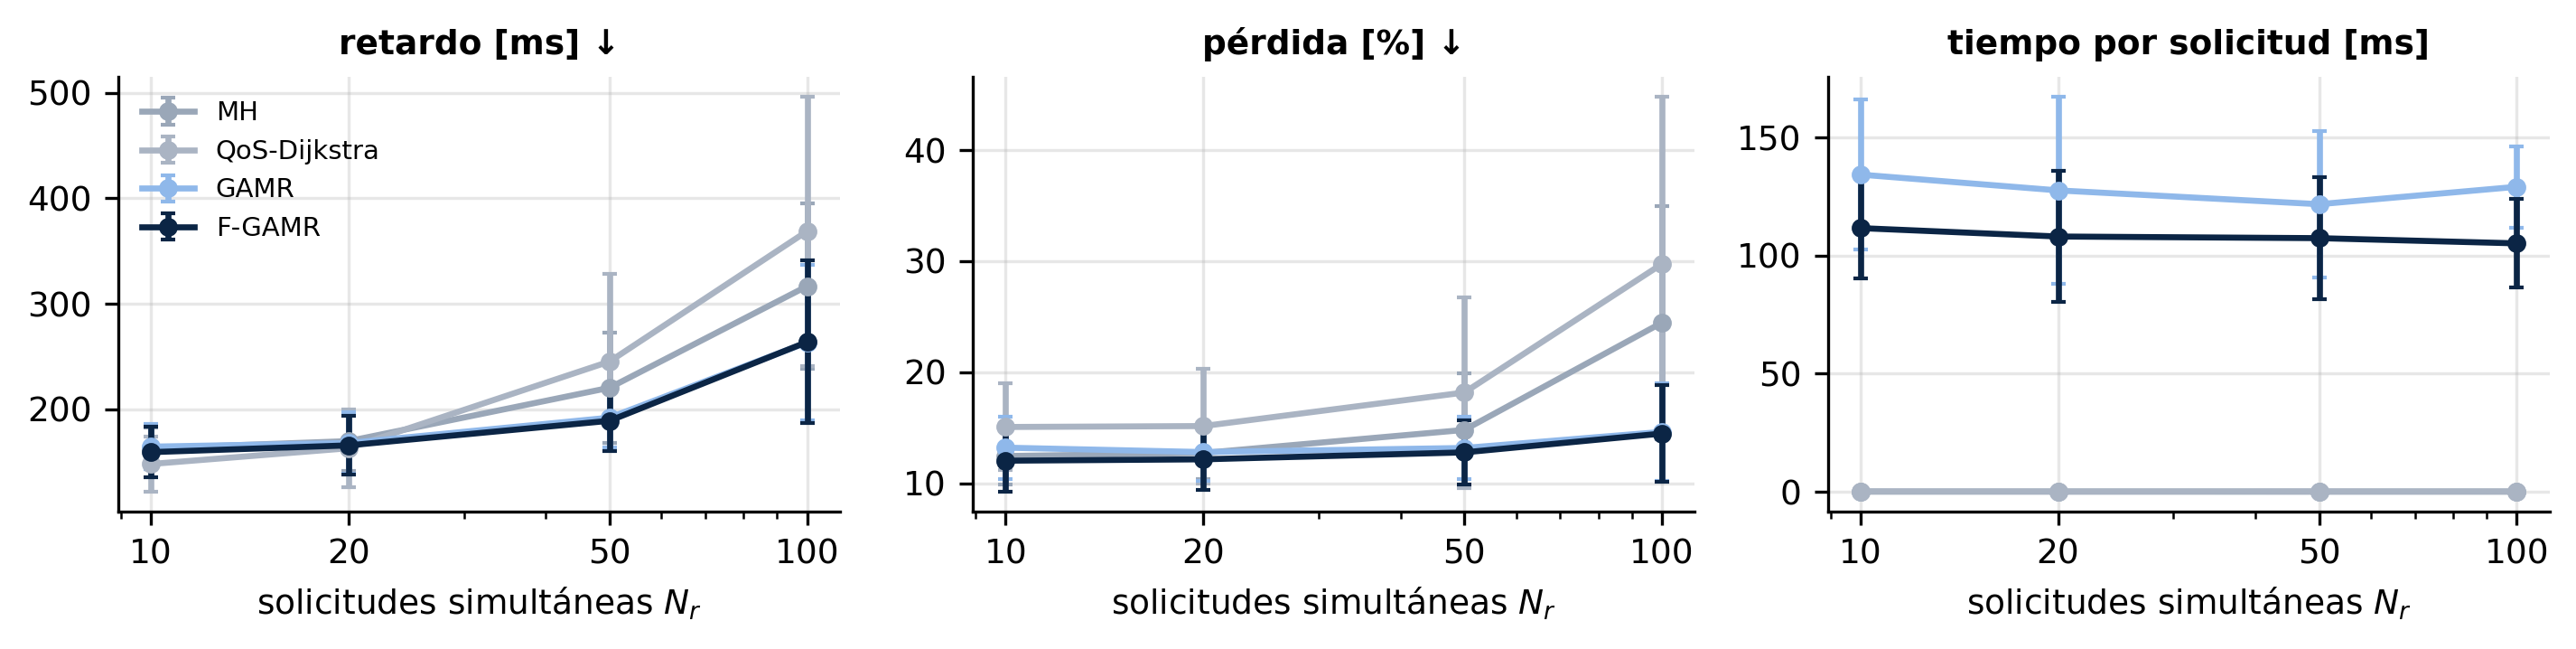

**Δ% frente a GAMR** (* = p < 0.05)

metrica          delay_ms  loss_pct  tiempo_s
n_r algoritmo                                
10  F-GAMR          +3.2%    +8.9%*   +16.9%*
    MH              +1.0%    +5.7%*  +100.0%*
    QoS-Dijkstra  +10.0%*    -14.1%   +99.9%*
20  F-GAMR          +1.3%    +5.1%*   +15.3%*
    MH              -1.1%     +0.6%  +100.0%*
    QoS-Dijkstra    +3.0%   -18.3%*   +99.9%*
50  F-GAMR          +1.5%    +3.0%*   +11.8%*
    MH            -14.7%*    -12.3%  +100.0%*
    QoS-Dijkstra  -27.7%*   -37.9%*   +99.9%*
100 F-GAMR          -0.1%     +1.0%   +18.5%*
    MH            -20.2%*   -67.2%*  +100.0%*
    QoS-Dijkstra  -40.0%*  -103.4%*   +99.9%*

In [12]:
if 'E2' in out:
    display(out['E2'])
    display(Image(filename=str(DIR_FIGS / 'E2_escalabilidad.png'), width=950))
    display(Markdown('**Δ% frente a GAMR** (* = p < 0.05)'))
    display(tabla_delta(out['E2_wilcoxon'], col_grupo='n_r'))

## 13. E3 — Robustez ante el desorden del ancho de banda β (Chinanet, Nₛ = 2, Nᵣ = 100, 10 semillas)

delay_ms       loss_pct  rho_max_pct
beta_pct algoritmo                                          
0        MH         195.1 ± 71.7   11.37 ± 4.09  82.8 ± 16.0
         LCP-WAC*   189.7 ± 75.2   10.12 ± 4.44  82.0 ± 18.1
         GAMR       193.1 ± 74.8   10.83 ± 4.17  79.3 ± 20.6
         F-GAMR     191.9 ± 76.4   10.35 ± 4.28  79.1 ± 20.8
5        MH         219.3 ± 60.6  17.28 ± 10.38  94.6 ± 10.3
         LCP-WAC*   211.4 ± 69.1  16.26 ± 10.66   95.5 ± 6.2
         GAMR       200.5 ± 77.4  15.53 ± 11.31  85.6 ± 14.7
         F-GAMR     199.4 ± 77.0  14.95 ± 11.46  85.5 ± 13.4
20       MH         222.3 ± 62.1  17.67 ± 10.06  95.2 ± 10.7
         LCP-WAC*   217.9 ± 68.1  16.74 ± 10.27   96.1 ± 7.3
         GAMR       207.7 ± 75.7  15.90 ± 11.02  88.0 ± 14.8
         F-GAMR     204.4 ± 76.7  15.40 ± 11.09  88.5 ± 12.5
55       MH         231.4 ± 68.5  20.59 ± 10.24   96.5 ± 8.2
         LCP-WAC*   229.0 ± 69.1   20.21 ± 9.97   96.2 ± 8.8
         GAMR       225.0 ± 74.4  19.26 ± 10.92  92.0 ± 11.2
         F-GAMR     225.1 ± 72.8  18.99 ± 10.95  92.5 ± 10.8

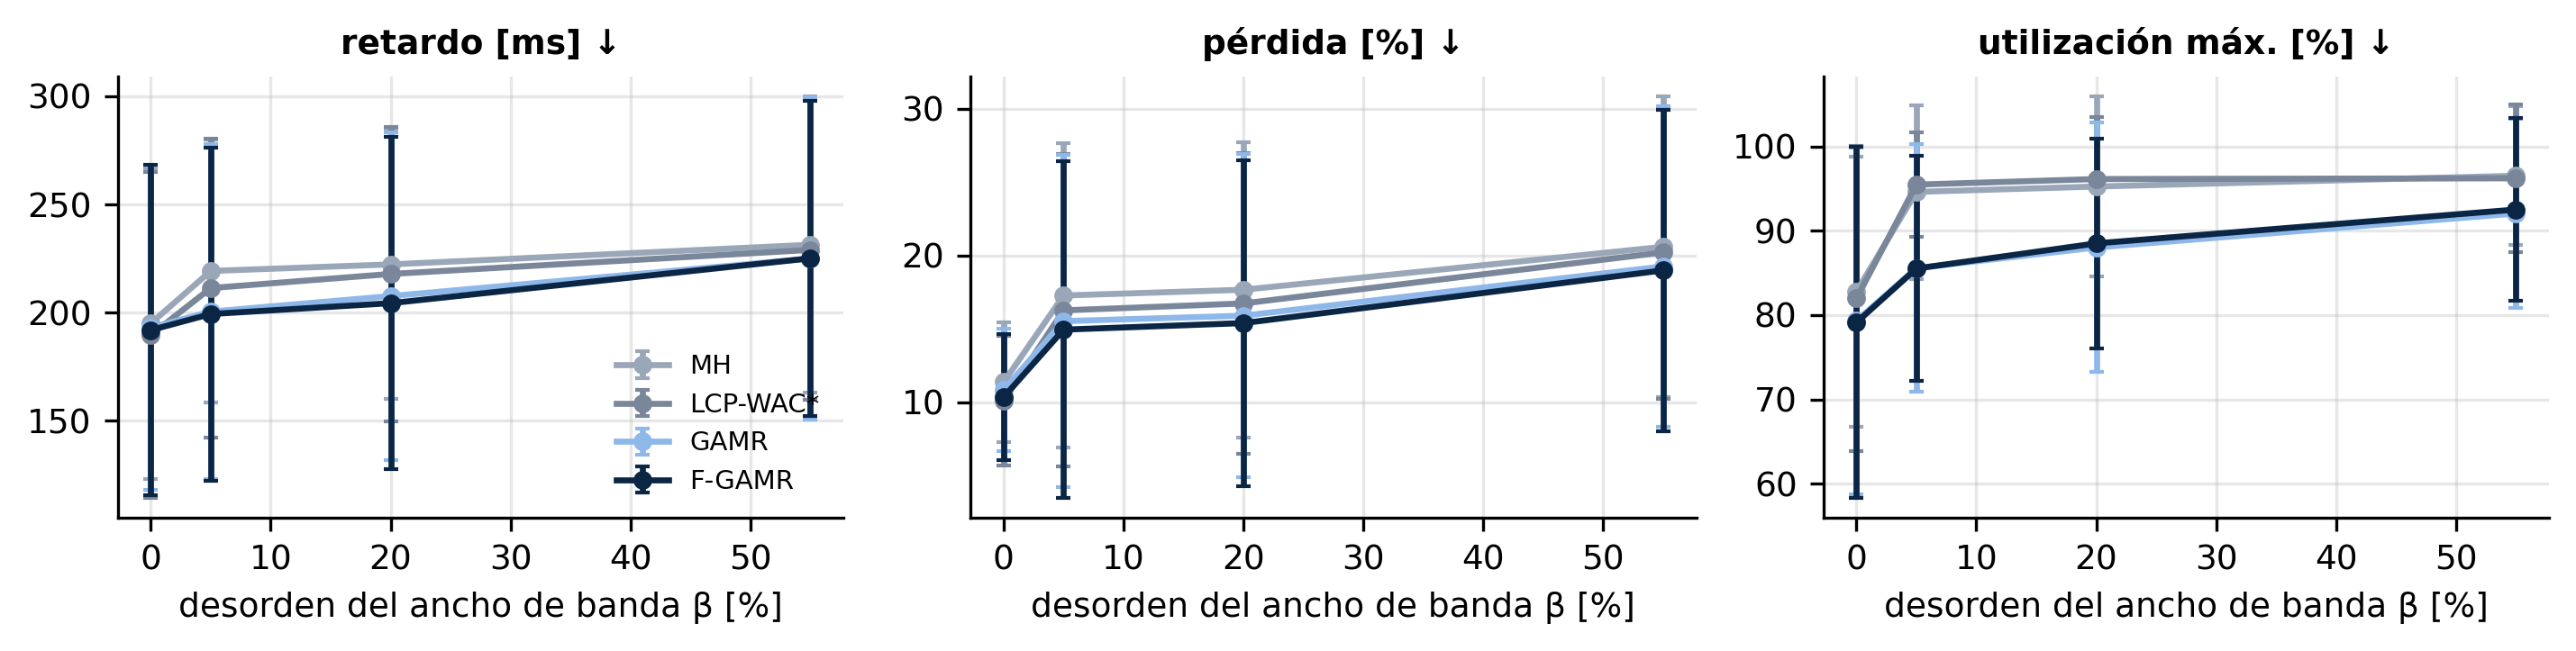

**Δ% frente a GAMR** (* = p < 0.05)

metrica            delay_ms loss_pct
beta_pct algoritmo                  
0        F-GAMR       +0.6%   +4.4%*
         LCP-WAC*     +1.8%   +6.6%*
         MH           -1.0%   -4.9%*
5        F-GAMR       +0.6%   +3.7%*
         LCP-WAC*    -5.4%*    -4.7%
         MH           -9.4%  -11.2%*
20       F-GAMR       +1.6%   +3.2%*
         LCP-WAC*     -4.9%    -5.2%
         MH           -7.0%  -11.1%*
55       F-GAMR       -0.0%    +1.4%
         LCP-WAC*     -1.8%    -5.0%
         MH           -2.8%   -6.9%*

In [13]:
if 'E3' in out:
    display(out['E3'])
    display(Image(filename=str(DIR_FIGS / 'E3_beta.png'), width=950))
    display(Markdown('**Δ% frente a GAMR** (* = p < 0.05)'))
    display(tabla_delta(out['E3_wilcoxon'], col_grupo='beta_pct'))

## 14. Resumen numérico automático
Archivo `results/tables/resumen_resultados.md` (insumo directo para el informe y la presentación).

In [14]:
display(Markdown((DIR_TABLAS / 'resumen_resultados.md').read_text(encoding='utf-8')))

# Resumen de resultados (generado automáticamente)

## E1 — F-GAMR y ablación frente a GAMR original (Δ% medio, p de Wilcoxon pareado, 30 semillas)

| escenario | variante | métrica | Δ% (>0 = mejor) | p |
|---|---|---|---|---|
| Chinanet · β=5% | F-GAMR | HV | +8.2 | 1.9e-08 |
| Chinanet · β=5% | F-GAMR (FIS-1) | HV | +7.4 | 3.2e-06 |
| Chinanet · β=5% | F-GAMR (FIS-2) | HV | +1.8 | 0.16 |
| Chinanet · β=55% | F-GAMR | HV | +6.8 | 5.7e-07 |
| Chinanet · β=55% | F-GAMR (FIS-1) | HV | +6.2 | 3.8e-06 |
| Chinanet · β=55% | F-GAMR (FIS-2) | HV | -0.9 | 0.5 |
| Oxford · β=5% | F-GAMR | HV | +1.5 | 0.24 |
| Oxford · β=5% | F-GAMR (FIS-1) | HV | +1.2 | 0.49 |
| Oxford · β=5% | F-GAMR (FIS-2) | HV | +0.5 | 0.81 |
| Oxford · β=55% | F-GAMR | HV | +0.5 | 0.2 |
| Oxford · β=55% | F-GAMR (FIS-1) | HV | -0.9 | 0.72 |
| Oxford · β=55% | F-GAMR (FIS-2) | HV | -0.2 | 1 |
| Chinanet · β=5% | F-GAMR | IGD | +24.7 | 8.9e-05 |
| Chinanet · β=5% | F-GAMR (FIS-1) | IGD | +29.6 | 8.9e-05 |
| Chinanet · β=5% | F-GAMR (FIS-2) | IGD | +8.5 | 0.077 |
| Chinanet · β=55% | F-GAMR | IGD | +19.6 | 0.00095 |
| Chinanet · β=55% | F-GAMR (FIS-1) | IGD | +16.7 | 0.0019 |
| Chinanet · β=55% | F-GAMR (FIS-2) | IGD | -5.2 | 0.63 |
| Oxford · β=5% | F-GAMR | IGD | -11.5 | 0.27 |
| Oxford · β=5% | F-GAMR (FIS-1) | IGD | -9.8 | 0.19 |
| Oxford · β=5% | F-GAMR (FIS-2) | IGD | +9.8 | 0.18 |
| Oxford · β=55% | F-GAMR | IGD | -7.8 | 0.97 |
| Oxford · β=55% | F-GAMR (FIS-1) | IGD | -13.1 | 0.22 |
| Oxford · β=55% | F-GAMR (FIS-2) | IGD | +2.4 | 0.54 |
| Chinanet · β=5% | F-GAMR | tiempo_s | +7.7 | 0.013 |
| Chinanet · β=5% | F-GAMR (FIS-1) | tiempo_s | +11.8 | 7.1e-05 |
| Chinanet · β=5% | F-GAMR (FIS-2) | tiempo_s | -5.2 | 0.24 |
| Chinanet · β=55% | F-GAMR | tiempo_s | +7.3 | 0.029 |
| Chinanet · β=55% | F-GAMR (FIS-1) | tiempo_s | +11.2 | 0.0012 |
| Chinanet · β=55% | F-GAMR (FIS-2) | tiempo_s | -1.8 | 0.34 |
| Oxford · β=5% | F-GAMR | tiempo_s | +16.7 | 2.4e-05 |
| Oxford · β=5% | F-GAMR (FIS-1) | tiempo_s | +18.4 | 6e-06 |
| Oxford · β=5% | F-GAMR (FIS-2) | tiempo_s | -1.5 | 0.57 |
| Oxford · β=55% | F-GAMR | tiempo_s | +18.3 | 6.9e-07 |
| Oxford · β=55% | F-GAMR (FIS-1) | tiempo_s | +19.3 | 5.7e-07 |
| Oxford · β=55% | F-GAMR (FIS-2) | tiempo_s | -1.1 | 0.95 |
| Chinanet · β=5% | F-GAMR | delay_ms | -0.3 | 0.84 |
| Chinanet · β=5% | F-GAMR (FIS-1) | delay_ms | +1.2 | 2.4e-05 |
| Chinanet · β=5% | F-GAMR (FIS-2) | delay_ms | -1.2 | 0.015 |
| Chinanet · β=55% | F-GAMR | delay_ms | -1.2 | 0.07 |
| Chinanet · β=55% | F-GAMR (FIS-1) | delay_ms | +0.4 | 0.13 |
| Chinanet · β=55% | F-GAMR (FIS-2) | delay_ms | -2.3 | 1.4e-06 |
| Oxford · β=5% | F-GAMR | delay_ms | -1.3 | 0.025 |
| Oxford · β=5% | F-GAMR (FIS-1) | delay_ms | -0.6 | 0.48 |
| Oxford · β=5% | F-GAMR (FIS-2) | delay_ms | -1.2 | 0.014 |
| Oxford · β=55% | F-GAMR | delay_ms | -1.6 | 0.058 |
| Oxford · β=55% | F-GAMR (FIS-1) | delay_ms | +0.0 | 0.63 |
| Oxford · β=55% | F-GAMR (FIS-2) | delay_ms | -0.7 | 0.073 |
| Chinanet · β=5% | F-GAMR | loss_pct | +6.1 | 1.9e-09 |
| Chinanet · β=5% | F-GAMR (FIS-1) | loss_pct | -0.5 | 0.63 |
| Chinanet · β=5% | F-GAMR (FIS-2) | loss_pct | +5.8 | 3.7e-09 |
| Chinanet · β=55% | F-GAMR | loss_pct | +5.3 | 5.6e-09 |
| Chinanet · β=55% | F-GAMR (FIS-1) | loss_pct | +0.2 | 0.52 |
| Chinanet · β=55% | F-GAMR (FIS-2) | loss_pct | +5.1 | 1.9e-09 |
| Oxford · β=5% | F-GAMR | loss_pct | +3.7 | 3.5e-08 |
| Oxford · β=5% | F-GAMR (FIS-1) | loss_pct | +0.3 | 0.11 |
| Oxford · β=5% | F-GAMR (FIS-2) | loss_pct | +2.7 | 0.00017 |
| Oxford · β=55% | F-GAMR | loss_pct | +2.8 | 9.9e-05 |
| Oxford · β=55% | F-GAMR (FIS-1) | loss_pct | -0.5 | 0.73 |
| Oxford · β=55% | F-GAMR (FIS-2) | loss_pct | +1.8 | 0.052 |

## E1 — F-GAMR frente a las tres líneas base

| escenario | referencia | métrica | Δ% | p |
|---|---|---|---|---|
| Chinanet · β=5% | GAMR | HV | +8.2 | 1.9e-08 |
| Chinanet · β=55% | GAMR | HV | +6.8 | 5.7e-07 |
| Oxford · β=5% | GAMR | HV | +1.5 | 0.24 |
| Oxford · β=55% | GAMR | HV | +0.5 | 0.2 |
| Chinanet · β=5% | GAMR | IGD | +24.7 | 8.9e-05 |
| Chinanet · β=55% | GAMR | IGD | +19.6 | 0.00095 |
| Oxford · β=5% | GAMR | IGD | -11.5 | 0.27 |
| Oxford · β=55% | GAMR | IGD | -7.8 | 0.97 |
| Chinanet · β=5% | GAMR | tiempo_s | +7.7 | 0.013 |
| Chinanet · β=55% | GAMR | tiempo_s | +7.3 | 0.029 |
| Oxford · β=5% | GAMR | tiempo_s | +16.7 | 2.4e-05 |
| Oxford · β=55% | GAMR | tiempo_s | +18.3 | 6.9e-07 |
| Chinanet · β=5% | GAMR | delay_ms | -0.3 | 0.84 |
| Chinanet · β=55% | GAMR | delay_ms | -1.2 | 0.07 |
| Oxford · β=5% | GAMR | delay_ms | -1.3 | 0.025 |
| Oxford · β=55% | GAMR | delay_ms | -1.6 | 0.058 |
| Chinanet · β=5% | GAMR | loss_pct | +6.1 | 1.9e-09 |
| Chinanet · β=55% | GAMR | loss_pct | +5.3 | 5.6e-09 |
| Oxford · β=5% | GAMR | loss_pct | +3.7 | 3.5e-08 |
| Oxford · β=55% | GAMR | loss_pct | +2.8 | 9.9e-05 |
| Chinanet · β=5% | NSGA-II | HV | +9.7 | 1.2e-06 |
| Chinanet · β=55% | NSGA-II | HV | +7.3 | 1.2e-06 |
| Oxford · β=5% | NSGA-II | HV | +12.0 | 5.7e-07 |
| Oxford · β=55% | NSGA-II | HV | +9.9 | 1.6e-05 |
| Chinanet · β=5% | NSGA-II | IGD | +30.1 | 0.00026 |
| Chinanet · β=55% | NSGA-II | IGD | +22.1 | 0.0047 |
| Oxford · β=5% | NSGA-II | IGD | +28.9 | 0.0016 |
| Oxford · β=55% | NSGA-II | IGD | +29.2 | 0.00087 |
| Chinanet · β=5% | NSGA-II | tiempo_s | +24.6 | 1.9e-09 |
| Chinanet · β=55% | NSGA-II | tiempo_s | +25.0 | 6.1e-08 |
| Oxford · β=5% | NSGA-II | tiempo_s | +26.7 | 3.7e-09 |
| Oxford · β=55% | NSGA-II | tiempo_s | +28.8 | 2.6e-08 |
| Chinanet · β=5% | NSGA-II | delay_ms | -0.0 | 0.78 |
| Chinanet · β=55% | NSGA-II | delay_ms | +0.5 | 0.61 |
| Oxford · β=5% | NSGA-II | delay_ms | +0.3 | 0.18 |
| Oxford · β=55% | NSGA-II | delay_ms | -0.4 | 0.7 |
| Chinanet · β=5% | NSGA-II | loss_pct | +6.4 | 5.6e-09 |
| Chinanet · β=55% | NSGA-II | loss_pct | +6.1 | 5.6e-09 |
| Oxford · β=5% | NSGA-II | loss_pct | +4.2 | 1.9e-09 |
| Oxford · β=55% | NSGA-II | loss_pct | +3.1 | 0.00014 |
| Chinanet · β=5% | MH | tiempo_s | -1659853.0 | 1.9e-09 |
| Chinanet · β=55% | MH | tiempo_s | -1772800.9 | 1.9e-09 |
| Oxford · β=5% | MH | tiempo_s | -2845796.4 | 1.9e-09 |
| Oxford · β=55% | MH | tiempo_s | -2731969.5 | 1.9e-09 |
| Chinanet · β=5% | MH | delay_ms | +1.7 | 0.0066 |
| Chinanet · β=55% | MH | delay_ms | +1.5 | 0.055 |
| Oxford · β=5% | MH | delay_ms | +11.5 | 2.3e-06 |
| Oxford · β=55% | MH | delay_ms | +8.0 | 0.00014 |
| Chinanet · β=5% | MH | loss_pct | +10.8 | 3.7e-09 |
| Chinanet · β=55% | MH | loss_pct | +9.9 | 3.7e-09 |
| Oxford · β=5% | MH | loss_pct | +14.0 | 5.1e-06 |
| Oxford · β=55% | MH | loss_pct | +19.9 | 1.6e-07 |

## E2 — escalabilidad (vs GAMR)

| n_r | variante | métrica | Δ% | p |
|---|---|---|---|---|
| 10 | F-GAMR | delay_ms | +3.2 | 0.28 |
| 10 | MH | delay_ms | +1.0 | 0.77 |
| 10 | QoS-Dijkstra | delay_ms | +10.0 | 0.002 |
| 20 | F-GAMR | delay_ms | +1.3 | 0.23 |
| 20 | MH | delay_ms | -1.1 | 0.32 |
| 20 | QoS-Dijkstra | delay_ms | +3.0 | 0.084 |
| 50 | F-GAMR | delay_ms | +1.5 | 0.92 |
| 50 | MH | delay_ms | -14.7 | 0.02 |
| 50 | QoS-Dijkstra | delay_ms | -27.7 | 0.027 |
| 100 | F-GAMR | delay_ms | -0.1 | 0.85 |
| 100 | MH | delay_ms | -20.2 | 0.0039 |
| 100 | QoS-Dijkstra | delay_ms | -40.0 | 0.002 |
| 10 | F-GAMR | loss_pct | +8.9 | 0.0039 |
| 10 | MH | loss_pct | +5.7 | 0.027 |
| 10 | QoS-Dijkstra | loss_pct | -14.1 | 0.064 |
| 20 | F-GAMR | loss_pct | +5.1 | 0.0098 |
| 20 | MH | loss_pct | +0.6 | 0.62 |
| 20 | QoS-Dijkstra | loss_pct | -18.3 | 0.037 |
| 50 | F-GAMR | loss_pct | +3.0 | 0.0039 |
| 50 | MH | loss_pct | -12.3 | 0.13 |
| 50 | QoS-Dijkstra | loss_pct | -37.9 | 0.002 |
| 100 | F-GAMR | loss_pct | +1.0 | 0.16 |
| 100 | MH | loss_pct | -67.2 | 0.0039 |
| 100 | QoS-Dijkstra | loss_pct | -103.4 | 0.0039 |
| 10 | F-GAMR | tiempo_s | +16.9 | 0.0098 |
| 10 | MH | tiempo_s | +100.0 | 0.002 |
| 10 | QoS-Dijkstra | tiempo_s | +99.9 | 0.002 |
| 20 | F-GAMR | tiempo_s | +15.3 | 0.037 |
| 20 | MH | tiempo_s | +100.0 | 0.002 |
| 20 | QoS-Dijkstra | tiempo_s | +99.9 | 0.002 |
| 50 | F-GAMR | tiempo_s | +11.8 | 0.049 |
| 50 | MH | tiempo_s | +100.0 | 0.002 |
| 50 | QoS-Dijkstra | tiempo_s | +99.9 | 0.002 |
| 100 | F-GAMR | tiempo_s | +18.5 | 0.0039 |
| 100 | MH | tiempo_s | +100.0 | 0.002 |
| 100 | QoS-Dijkstra | tiempo_s | +99.9 | 0.002 |

## E3 — desorden β (vs GAMR)

| beta_pct | variante | métrica | Δ% | p |
|---|---|---|---|---|
| 0 | F-GAMR | delay_ms | +0.6 | 0.19 |
| 0 | LCP-WAC* | delay_ms | +1.8 | 0.084 |
| 0 | MH | delay_ms | -1.0 | 0.49 |
| 5 | F-GAMR | delay_ms | +0.6 | 0.28 |
| 5 | LCP-WAC* | delay_ms | -5.4 | 0.049 |
| 5 | MH | delay_ms | -9.4 | 0.19 |
| 20 | F-GAMR | delay_ms | +1.6 | 0.32 |
| 20 | LCP-WAC* | delay_ms | -4.9 | 0.084 |
| 20 | MH | delay_ms | -7.0 | 0.23 |
| 55 | F-GAMR | delay_ms | -0.0 | 0.62 |
| 55 | LCP-WAC* | delay_ms | -1.8 | 0.56 |
| 55 | MH | delay_ms | -2.8 | 0.56 |
| 0 | F-GAMR | loss_pct | +4.4 | 0.002 |
| 0 | LCP-WAC* | loss_pct | +6.6 | 0.002 |
| 0 | MH | loss_pct | -4.9 | 0.014 |
| 5 | F-GAMR | loss_pct | +3.7 | 0.002 |
| 5 | LCP-WAC* | loss_pct | -4.7 | 1 |
| 5 | MH | loss_pct | -11.2 | 0.0039 |
| 20 | F-GAMR | loss_pct | +3.2 | 0.002 |
| 20 | LCP-WAC* | loss_pct | -5.2 | 0.56 |
| 20 | MH | loss_pct | -11.1 | 0.002 |
| 55 | F-GAMR | loss_pct | +1.4 | 0.16 |
| 55 | LCP-WAC* | loss_pct | -5.0 | 0.7 |
| 55 | MH | loss_pct | -6.9 | 0.037 |


## 15. Discusión crítica, casos de fallo y limitaciones

### Respuesta a las preguntas de investigación
**P1 — ¿La exploración guiada por FIS-1 mejora el frente y la convergencia?** Sí, con matices (E1, 30 semillas, Wilcoxon pareado):

| Escenario | HV vs GAMR | IGD vs GAMR | Tiempo vs GAMR | Lectura |
|---|---|---|---|---|
| Chinanet β = 5 % | **+8.2 %** (p = 2·10⁻⁸) | **−24.7 %** (p < 10⁻⁴) | **−7.7 %** (p = 0.013) | mejora clara |
| Chinanet β = 55 % | **+6.8 %** (p < 10⁻⁶) | **−19.6 %** (p < 10⁻³) | **−7.3 %** (p = 0.029) | mejora clara |
| Oxford β = 5 % | +1.5 % (n.s.) | +11.5 % peor (n.s.) | **−16.7 %** (p < 10⁻⁴) | más rápido, frente igual |
| Oxford β = 55 % | +0.5 % (n.s.) | +7.8 % peor (n.s.) | **−18.3 %** (p < 10⁻⁶) | más rápido, frente igual |

Frente a **NSGA-II**, F-GAMR mejora el HV entre 7 % y 12 %, el IGD entre 22 % y 30 % y el tiempo entre 25 % y 29 % en los cuatro escenarios (p < 0.005).

**P2 — ¿FIS-2 mejora la QoS de la ruta instalada?** Sí. F-GAMR obtiene la **menor pérdida realizada** en los cuatro escenarios: entre 2.8 % y 6.1 % menos que GAMR (p ≤ 10⁻⁴). El costo en retardo es de +0.3 % a +1.6 % y solo es significativo en Oxford con β = 5 %. Sobre los mismos frentes de GAMR, FIS-2 reduce la pérdida entre 1.4 % y 6.1 % (p < 0.03) y domina de Pareto al punto rodilla en 3 de 4 escenarios.

### Ablación: cada componente hace una cosa distinta
* **FIS-1 → frente y tiempo.** Por sí solo sube el HV de Chinanet entre 6 % y 7 % y recorta el tiempo entre 11 % y 19 % (p < 0.002). En cambio, no cambia la pérdida realizada.
* **FIS-2 → ruta instalada.** Por sí solo no altera el frente (p > 0.07, lo esperado porque actúa después de la evolución), pero explica toda la reducción de pérdida.
* Por lo tanto, los dos sistemas difusos son **complementarios**, no redundantes.

### Por qué funciona
En 2000 caminatas sobre una instancia de Oxford (Sección 5.2), la ruta inicial media pasa de 541 a 485 ms y su pérdida de 45 % a 36 %. Como la población arranca mejor, el HV inicial es mayor y la parada por estancamiento (Ec. 13) se activa antes: en Oxford, unas 50 generaciones frente a 62 de GAMR. FIS-2 cambia un criterio topológico (el solapamiento) por uno que mira la QoS que percibe el usuario.

### Escalabilidad (E2) y desorden de la red (E3)
* **E2.** Con Nᵣ = 100 las heurísticas colapsan: Min-Hop llega a 317 ms y 24.5 % de pérdida, y QoS-Dijkstra a 369 ms y 29.7 %, mientras los evolutivos se mantienen en unos 264 ms y 14.5 %. F-GAMR reduce la pérdida de GAMR en 8.9 %, 5.1 % y 3.0 % para Nᵣ = 10, 20 y 50 (p < 0.01); con Nᵣ = 100 la mejora (−1.0 %) no es significativa. El tiempo baja entre 12 % y 19 % en todas las cargas.
* **E3.** Con β = 0 la red no cambia y la predicción histórica de LCP-WAC* es exacta, así que este gana (189.7 ms y 10.1 %), igual que en el paper. Con β ≥ 5 % la predicción queda obsoleta y los evolutivos lo superan. F-GAMR reduce la pérdida de GAMR en 3.2–4.4 % para β ≤ 20 % (p = 0.002); con β = 55 % la mejora no es significativa.

### Casos de fallo (análisis honesto)
1. **Oxford no mejora en HV ni IGD.** Es una topología poco mallada (diámetro 7, grado medio 2.6, solo 3 triángulos). Al haber pocas alternativas, el sesgo de FIS-1 reduce la diversidad: 22 rutas iniciales distintas frente a 36 con la caminata uniforme. Por eso el IGD empeora un 8–12 %, aunque sin significancia. El parámetro κ debería depender de la conectividad de la red.
2. **El beneficio se desvanece con β = 55 % y con Nᵣ = 100.** La ruta se elige con el estado medido Δᵗ pero se usa en Δᵗ⁺¹. Si la red cambia mucho, o si la congestión domina todo, elegir bien el compromiso deja de marcar diferencia.
3. **FIS-2 sube un poco la utilización máxima** (ρ_max, +1 a +3 puntos), porque prioriza rutas de baja pérdida aunque compartan enlaces.
4. **Resultado negativo: el control adaptativo de α.** Adaptar α o inyectar inmigrantes según la volatilidad de la red dio un HV entre −6 % y +8 % según el escenario y hasta +72 % de tiempo; con α = 0.8, el HV bajó 19 %. Subir α concentra la población en el tramo memorizado y colapsa la diversidad. Además, como la mutación por inserción siempre alarga la ruta, subir p_m solo agrega desvíos.

### Limitaciones
* El plano de datos es un **modelo fluido** (cola M/M/1 acotada más pérdida por desborde), no Mininet/TCP. Los valores absolutos (ms, %) no son comparables con el paper; las comparaciones entre algoritmos sí lo son, porque todos se evalúan en el mismo simulador.
* **LCP-WAC\*** es un proxy sin LSTM.
* Las reglas y funciones de pertenencia se diseñaron con conocimiento experto y se calibraron con solo 4 semillas de validación.
* Solo se evaluaron dos topologías medianas (20 y 42 switches).
* Los tiempos corresponden a Python puro, en un solo hilo por algoritmo.

## 16. Conclusiones y trabajo futuro

**Conclusiones**
* F-GAMR agrega a GAMR **conocimiento interpretable sobre la QoS sin entrenamiento**, y lo hace sin cambiar su complejidad asintótica.
* **FIS-1** (exploración guiada) mejora significativamente el frente en la topología más mallada: en Chinanet el HV sube 7–8 % y el IGD baja 20–25 %. Además, reduce el tiempo de cómputo en todos los escenarios (−7 % a −19 %).
* **FIS-2** (selector de compromiso) reduce la pérdida de paquetes realizada entre 2.8 % y 6.1 %, con un costo de retardo menor al 2 %.
* La evaluación estadística (30 semillas, Wilcoxon) y la ablación permiten atribuir cada mejora a su componente. La calibración en semillas disjuntas, incluido el resultado negativo del control de α, respalda que los resultados no están sobreajustados a las semillas de evaluación.

**Trabajo futuro**
1. Ajustar las funciones de pertenencia y las reglas con un AG (sistema genético-difuso), en lugar de diseñarlas a mano.
2. Hacer κ adaptativo según la conectividad de la topología, para no perder diversidad en redes poco malladas como Oxford.
3. Usar una memoria PRSM indexada por región del host (por ejemplo, mediante *clustering* espectral), atacando la debilidad 3.
4. Validar en Mininet + Ryu con tráfico TCP real y en topologías más grandes.

## 17. Reproducibilidad

| Paso | Comando |
|---|---|
| Instalar | `python -m venv .venv` → activar → `pip install -r requirements.txt` |
| Pruebas | `python -m pytest -q` (7 pruebas, < 10 s) |
| Experimentos + tablas + figuras | `python run_reproduction.py` (≈ 1.5 h, 7 procesos) · `--modo rapido` (≈ 5 min) |
| Solo regenerar tablas/figuras | `python run_reproduction.py --solo-reporte` |
| Calibración (semillas 500–503) | `python scripts/calibracion.py` (≈ 15 min) |
| Este notebook | Run All con `MODO = 'completo'` (carga `results/raw_logs/`) |
| Figuras y tablas del informe | `python scripts/informe_assets.py` (< 1 min) |
| Informe PDF | `report_ieee/main.tex` (pdflatex → bibtex → pdflatex ×2) |

* **Determinismo:** cada tarea (experimento, semilla) fija la semilla de la red (`10 000 + 97·s`) y la de cada algoritmo (`1000·s + k`); los algoritmos no consumen el generador de la red, así que todos ven las mismas solicitudes y estados. Repetir la corrida reproduce los CSV exactamente (salvo los tiempos de CPU).
* **Hardware de referencia:** Intel Core i5-10210U (4 núcleos / 8 hilos), Windows 11, Python 3.12.3. Los tiempos absolutos dependen del equipo; las comparaciones de tiempo son válidas porque todos los algoritmos de una tarea corren en el mismo proceso, uno tras otro.
* **Sin dependencias frágiles:** solo numpy, scipy, pandas, networkx y matplotlib; la lógica difusa es propia (`src/fuzzy_logic.py`).